# Part B: ResNet-18 Transfer Learning for Multiclass Blood Cell Classification

# 1. Introduction

Biomedical image analysis uses computational techniques to extract meaningful information from medical and biological images.

In this project, transfer learning is investigated for the classification of different blood cell types using microscopic images from the BloodMNIST dataset.

A ResNet-18 convolutional neural network pretrained on ImageNet is adapted to classify eight blood cell categories.

The study investigates two configurations of the pretrained model: a frozen feature extractor and a fine-tuned network.

### 1.1 Research Question

To what extent does fine-tuning an ImageNet-pretrained ResNet-18 improve multiclass blood cell classification compared with using a frozen pretrained backbone?

### 1.2 Research Objectives

1. Explore the BloodMNIST dataset and its class distribution.
2. Implement an ImageNet-pretrained ResNet-18 model.
3. Evaluate a frozen pretrained backbone.
4. Fine-tune ResNet-18 for blood cell classification.
5. Compare both model configurations.
6. Evaluate class-wise classification performance.
7. Visualise model predictions using Grad-CAM.
8. Analyse classification errors, limitations and result reliability.

### 1.3 Dataset Overview

- **Dataset:** BloodMNIST
- **Dataset collection:** MedMNIST
- **Image modality:** Blood cell microscopy
- **Image resolution:** 128 × 128 pixels
- **Image channels:** RGB
- **Number of classes:** 8
- **Total number of images:** 17,092
- **Dataset licence:** Creative Commons Attribution 4.0 International (CC BY 4.0)

### 1.4 Experimental Hypothesis

The primary hypothesis is that fine-tuning an ImageNet-pretrained ResNet-18 will improve classification performance, particularly macro F1-score, compared with using a frozen pretrained backbone.

This hypothesis is investigated experimentally using the official training, validation and test splits.

### 1.5 Scope of the Study

This project focuses on educational and research-based blood cell image classification. The results are not intended to replace laboratory examination or provide clinical diagnoses.

# 2. Environment Setup and Reproducibility

This section establishes the computational environment used for the experiments.

The project is implemented using Python and PyTorch in the SRH Data Lab environment. GPU acceleration is used to speed up model training.

Software versions, hardware information and random seeds are recorded to support reproducibility. The same environment configuration is maintained across both experimental configurations.

### 2.1 Installing Required Dependencies

The project uses MedMNIST to access the BloodMNIST dataset and Seaborn for data visualisation.

The following command installs these additional libraries if they are not already available in the environment.

In [1]:
%pip install medmnist seaborn

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.7/13.7 MB 92.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [medmnist]5/7 [seaborn]mage]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### 2.2 Importing Required Libraries

In this subsection, we import the Python libraries required for
data handling, image visualisation, deep learning, model evaluation,
and reproducibility.

All major imports are kept together in one cell to ensure that
the notebook can be executed from top to bottom without relying
on previously executed cells.

In [2]:
# Operating system and system information
import os
import sys
import random
import platform
import urllib.request

# Data handling and numerical operations
import numpy as np
import pandas as pd

# Image visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Deep learning libraries
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torchvision import models

# BloodMNIST dataset
import medmnist
from medmnist import BloodMNIST

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Progress bar
from tqdm.auto import tqdm

print("All required libraries imported successfully.")
print("MedMNIST version:", medmnist.__version__)
print("Seaborn version:", sns.__version__)

All required libraries imported successfully.
MedMNIST version: 3.0.2
Seaborn version: 0.13.2


### 2.3 Checking Hardware and GPU Availability

Before training the deep learning models, we check the available
computing hardware and verify whether CUDA-enabled GPU acceleration
is available.

This is important because training ResNet-18 on a GPU can
significantly reduce computation time compared with CPU training.

We also record the PyTorch, Torchvision, CUDA, and GPU information
to document the experimental environment.

In [3]:
# Check Python and operating system information
print("Python version:", sys.version)
print("Operating system:", platform.platform())

# Check PyTorch and Torchvision versions
print("\nPyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

# Check whether CUDA is available
print("\nCUDA available:", torch.cuda.is_available())

# Select GPU if available; otherwise use CPU
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", DEVICE)

# Display GPU details when CUDA is available
if torch.cuda.is_available():
    print("CUDA version:", torch.version.cuda)
    print("GPU name:", torch.cuda.get_device_name(0))

    # Display available GPU memory
    gpu_memory = torch.cuda.get_device_properties(0).total_memory
    print("GPU memory:", round(gpu_memory / (1024 ** 3), 2), "GB")
else:
    print("No CUDA-enabled GPU detected. Training will use CPU.")

Python version: 3.11.13 (main, Jun  4 2025, 08:57:29) [GCC 11.4.0]
Operating system: Linux-5.15.0-191-generic-x86_64-with-glibc2.35

PyTorch version: 2.9.1+cu128
Torchvision version: 0.24.1+cu128

CUDA available: True
Selected device: cuda
CUDA version: 12.8
GPU name: NVIDIA RTX A6000
GPU memory: 47.4 GB


### 2.4 Setting Up Reproducibility

Reproducibility is important in deep learning experiments because
randomness can influence model initialisation, data shuffling,
and other training operations.

To improve reproducibility, we configure random seeds for Python,
NumPy, and PyTorch, along with CUDA-related random seeds and
deterministic operations where supported.

We will use three predefined random seeds (42, 43, and 44) for
repeated experiments. The same seed will be used for both the
frozen and fine-tuned ResNet-18 configurations in each paired run.

In [4]:
# Define the initial random seed
SEED = 42

# Set the seed for Python's random module
random.seed(SEED)

# Set the seed for NumPy
np.random.seed(SEED)

# Set the seed for PyTorch on CPU
torch.manual_seed(SEED)

# Set the seed for all available CUDA devices
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Configure deterministic behaviour where supported
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("Random seed:", SEED)
print("Reproducibility settings configured.")
print("Selected device:", DEVICE)

Random seed: 42
Reproducibility settings configured.
Selected device: cuda


# 3. Dataset Description and Exploration

This section describes the BloodMNIST dataset used in our
multiclass blood cell classification experiment.

Before developing and training the deep learning models,
we examine the dataset characteristics, image properties,
class distribution, and predefined data splits.

This initial exploration helps us understand the data and
identify any characteristics that may influence model
training and evaluation.

## 3.1 BloodMNIST Dataset Overview

BloodMNIST is part of the MedMNIST collection of biomedical
image datasets.

It consists of microscopic images of individual blood cells
collected from individuals without infection, hematologic
or oncologic disease, and without pharmacologic treatment
at the time of blood collection.

The dataset contains 17,092 images belonging to eight
different blood cell classes.

For this project, we use the 128 × 128 RGB version of
BloodMNIST to investigate multiclass blood cell classification.

The dataset provides predefined training, validation,
and testing splits, which will be retained throughout
our experiments.

## 3.2 Dataset Metadata and Class Information

We retrieve the official BloodMNIST metadata from the MedMNIST
library to examine the dataset specifications.

The metadata provides information about the classification
task, number of classes, image channels, dataset description,
and the predefined training, validation, and testing splits.

We also examine the class labels and their corresponding
numerical identifiers.

In [5]:
# Retrieve the official BloodMNIST metadata
dataset_info = medmnist.INFO["bloodmnist"]

# Display general dataset information
print("Dataset name:", dataset_info["python_class"])
print("Task:", dataset_info["task"])
print("Number of classes:", len(dataset_info["label"]))
print("Number of image channels:", dataset_info["n_channels"])

# Display the official dataset description
print("\nDataset description:")
print(dataset_info["description"])

# Display the number of samples in each split
print("\nOfficial dataset split sizes:")

for split, count in dataset_info["n_samples"].items():
    print(f"{split.capitalize()}: {count}")

# Display the class labels and their numerical identifiers
print("\nClass labels:")

for class_id, class_name in dataset_info["label"].items():
    print(f"{class_id}: {class_name}")

Dataset name: BloodMNIST
Task: multi-class
Number of classes: 8
Number of image channels: 3

Dataset description:
The BloodMNIST is based on a dataset of individual normal cells, captured from individuals without infection, hematologic or oncologic disease and free of any pharmacologic treatment at the moment of blood collection. It contains a total of 17,092 images and is organized into 8 classes. We split the source dataset with a ratio of 7:1:2 into training, validation and test set. The source images with resolution 3×360×363 pixels are center-cropped into 3×200×200, and then resized into 3×28×28.

Official dataset split sizes:
Train: 11959
Val: 1712
Test: 3421

Class labels:
0: basophil
1: eosinophil
2: erythroblast
3: immature granulocytes(myelocytes, metamyelocytes and promyelocytes)
4: lymphocyte
5: monocyte
6: neutrophil
7: platelet


## 3.3 Dataset Download and Loading

The BloodMNIST dataset is obtained from its official Zenodo
repository.

For this experiment, we use the 128 × 128 version of the
dataset rather than the original 28 × 28 version.

The downloaded dataset file is stored separately from the
notebook and will remain unchanged throughout the experiments.

### 3.3.1 Downloading the BloodMNIST 128 × 128 Dataset

We download the dataset only if it is not already available
at the specified destination.

This prevents unnecessary repeated downloads when the
notebook is executed again.

In [6]:
# Create a dedicated directory for the dataset
DATA_DIR = "./data"
os.makedirs(DATA_DIR, exist_ok=True)

# Define the official Zenodo download URL
DATA_URL = (
    "https://zenodo.org/records/10519652/files/"
    "bloodmnist_128.npz?download=1"
)

# Define the destination file path
DATA_PATH = os.path.join(DATA_DIR, "bloodmnist_128.npz")

# Download only when the dataset is not already present
if not os.path.isfile(DATA_PATH):

    print("Downloading BloodMNIST 128x128 dataset...")

    # Download to a temporary file first
    TEMP_PATH = DATA_PATH + ".part"

    try:
        urllib.request.urlretrieve(DATA_URL, TEMP_PATH)

        # Move the completed download to its final filename
        os.replace(TEMP_PATH, DATA_PATH)

        print("Dataset download completed.")

    except Exception:
        # Remove an incomplete temporary download, if present
        if os.path.exists(TEMP_PATH):
            os.remove(TEMP_PATH)
        raise

else:
    print("Dataset already exists. Download skipped.")

# Verify the downloaded file
print("\nDataset path:", os.path.abspath(DATA_PATH))
print("File size:", round(os.path.getsize(DATA_PATH) / (1024 ** 2), 2), "MB")
print("File exists:", os.path.isfile(DATA_PATH))

Dataset download completed.

Dataset path: /home/jovyan/data/bloodmnist_128.npz
File size: 542.71 MB
File exists: True


### 3.3.2 Loading the Dataset

After successfully downloading the dataset, we load the
NumPy archive file using NumPy's loading functionality.

The archive contains the predefined training, validation,
and testing splits, together with their corresponding labels.

We extract these arrays separately while preserving the
original image data and label assignments.

In [7]:
# Load the downloaded NumPy archive
blood_data = np.load(DATA_PATH)

# Extract images and labels from each official split
X_train = blood_data["train_images"]
y_train = blood_data["train_labels"]

X_val = blood_data["val_images"]
y_val = blood_data["val_labels"]

X_test = blood_data["test_images"]
y_test = blood_data["test_labels"]

# Display the number of samples in each split
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("\nValidation images:", X_val.shape)
print("Validation labels:", y_val.shape)

print("\nTesting images:", X_test.shape)
print("Testing labels:", y_test.shape)

# Display the image data type
print("\nImage data type:", X_train.dtype)

# Display the label data type
print("Label data type:", y_train.dtype)

Training images: (11959, 128, 128, 3)
Training labels: (11959, 1)

Validation images: (1712, 128, 128, 3)
Validation labels: (1712, 1)

Testing images: (3421, 128, 128, 3)
Testing labels: (3421, 1)

Image data type: uint8
Label data type: uint8


## 3.4 Dataset Structure and Image Properties

In this section, we examine the structure and basic properties
of the loaded BloodMNIST images.

We verify the image dimensions, colour channels, pixel intensity
range, and consistency of the dataset splits.

These checks help identify unexpected data issues before
preprocessing and model development.

### 3.4.1 Image Dimensions and Dataset Split Verification

We examine the structure of the training, validation, and testing datasets.

The image dimensions, number of samples, and corresponding label counts are checked to ensure consistency across all three splits.

We also verify the pixel intensity range and check for missing or infinite numerical values to identify potential data quality issues before preprocessing.

In [8]:
# Store the image arrays and labels in dictionaries
image_splits = {
    "Training": X_train,
    "Validation": X_val,
    "Testing": X_test
}

label_splits = {
    "Training": y_train,
    "Validation": y_val,
    "Testing": y_test
}

# Verify the properties of each dataset split
for split_name in image_splits:

    images = image_splits[split_name]
    labels = label_splits[split_name]

    print(f"\n{split_name} Set")
    print("-" * 40)

    # Check image dimensions and number of samples
    print("Number of images:", len(images))
    print("Image shape:", images.shape[1:])

    # Check whether the image and label counts match
    print("Number of labels:", len(labels))
    print("Image-label count matches:", len(images) == len(labels))

    # Examine pixel intensity range
    print("Minimum pixel value:", images.min())
    print("Maximum pixel value:", images.max())

    # Check for missing or invalid numerical values
    print("Contains NaN:", np.isnan(images).any())
    print("Contains infinite values:", np.isinf(images).any())


Training Set
----------------------------------------
Number of images: 11959
Image shape: (128, 128, 3)
Number of labels: 11959
Image-label count matches: True
Minimum pixel value: 1
Maximum pixel value: 255
Contains NaN: False
Contains infinite values: False

Validation Set
----------------------------------------
Number of images: 1712
Image shape: (128, 128, 3)
Number of labels: 1712
Image-label count matches: True
Minimum pixel value: 3
Maximum pixel value: 255
Contains NaN: False
Contains infinite values: False

Testing Set
----------------------------------------
Number of images: 3421
Image shape: (128, 128, 3)
Number of labels: 3421
Image-label count matches: True
Minimum pixel value: 2
Maximum pixel value: 255
Contains NaN: False
Contains infinite values: False


### 3.4.2 Pixel Intensity Distribution

We examine the pixel intensity distribution of the training images to understand how brightness values are distributed.

The analysis uses the first 100 training images, or all available images if fewer than 100 are present, to limit memory usage.

Pixel intensity values range from 0 to 255 for 8-bit images. We calculate descriptive statistics and visualise the distribution using a histogram.

This analysis provides an overview of image brightness characteristics before the preprocessing and normalisation steps.

Pixel Intensity Statistics
-----------------------------------
Minimum: 9
Maximum: 255
Mean: 182.17
Standard deviation: 55.05


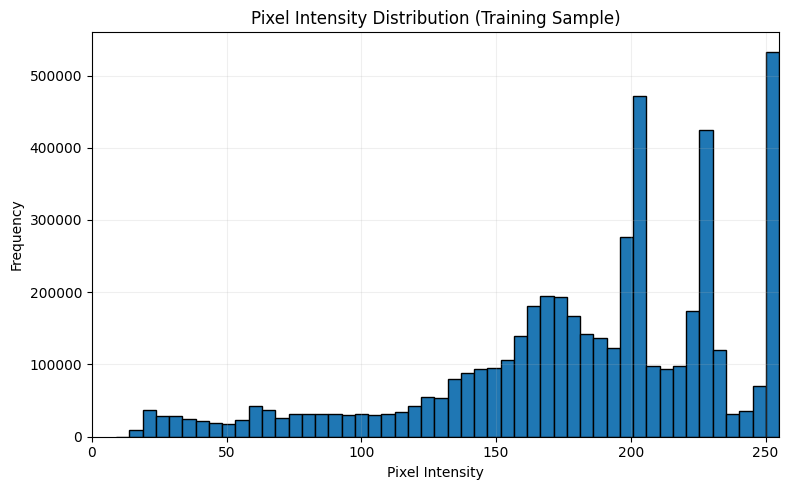

In [9]:
# Select a sample of training images for analysis
sample_size = min(100, len(X_train))
sample_images = X_train[:sample_size]

# Calculate the pixel intensity distribution
pixel_values = sample_images.flatten()

# Display descriptive statistics
print("Pixel Intensity Statistics")
print("-" * 35)
print("Minimum:", pixel_values.min())
print("Maximum:", pixel_values.max())
print("Mean:", round(pixel_values.mean(), 2))
print("Standard deviation:", round(pixel_values.std(), 2))

# Plot the pixel intensity histogram
plt.figure(figsize=(8, 5))

plt.hist(
    pixel_values,
    bins=50,
    edgecolor="black"
)

plt.title("Pixel Intensity Distribution (Training Sample)")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.xlim(0, 255)
plt.grid(alpha=0.2)
plt.tight_layout()

# Save the figure for the project results
os.makedirs("./figures", exist_ok=True)

plt.savefig(
    "./figures/pixel_intensity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 3.5 Class Distribution Analysis

Class distribution analysis helps us understand how samples
are distributed across the eight blood cell categories.

An imbalanced dataset may influence model training and
evaluation because classes with more samples can have
a greater influence on the learning process.

We examine the class distribution separately for the
training, validation, and testing sets.

For each class, we calculate the number of images and
its percentage of the corresponding dataset split.

In [10]:
# Define the class names using the official MedMNIST metadata
class_names = [
    dataset_info["label"][str(i)]
    for i in range(len(dataset_info["label"]))
]

# Create dictionaries containing the labels for each split
label_splits = {
    "Train": y_train,
    "Validation": y_val,
    "Test": y_test
}

# Create an empty list to store class distribution results
distribution_results = []

# Calculate class counts and percentages for each split
for split_name, labels in label_splits.items():

    # Convert labels from shape (N, 1) to (N,)
    labels_flat = labels.flatten()

    # Calculate the number of samples in each class
    class_counts = np.bincount(
        labels_flat.astype(int),
        minlength=len(class_names)
    )

    # Calculate the percentage of each class
    class_percentages = (
        class_counts / len(labels_flat)
    ) * 100

    # Store the results
    for class_id, class_name in enumerate(class_names):

        distribution_results.append({
            "Split": split_name,
            "Class ID": class_id,
            "Class": class_name,
            "Image Count": class_counts[class_id],
            "Percentage": round(class_percentages[class_id], 2)
        })

# Convert the results into a DataFrame
class_distribution_df = pd.DataFrame(distribution_results)

# Display the class distribution table
print("Class Distribution Across Dataset Splits")

display(class_distribution_df)

# Create a directory for saved results
os.makedirs("./results", exist_ok=True)

# Save the class distribution as a CSV file
class_distribution_df.to_csv(
    "./results/class_distribution.csv",
    index=False
)

print("\nClass distribution saved successfully.")

Class Distribution Across Dataset Splits


,Split,Class ID,Class,Image Count,Percentage
0,Train,0,basophil,852,7.12
1,Train,1,eosinophil,2181,18.24
2,Train,2,erythroblast,1085,9.07
3,Train,3,"immature granulocytes(myelocytes, metamyelocyt...",2026,16.94
4,Train,4,lymphocyte,849,7.10
5,Train,5,monocyte,993,8.30
6,Train,6,neutrophil,2330,19.48
7,Train,7,platelet,1643,13.74
8,Validation,0,basophil,122,7.13
9,Validation,1,eosinophil,312,18.22



Class distribution saved successfully.


### 3.5.1 Visualising Class Distribution

We visualise the class distribution using a grouped bar chart.

The chart compares the percentage of each blood cell category
across the training, validation, and testing sets.

Using percentages allows us to compare the relative class
distributions despite the different sizes of the three splits.

The resulting figure is saved for documentation and reporting.

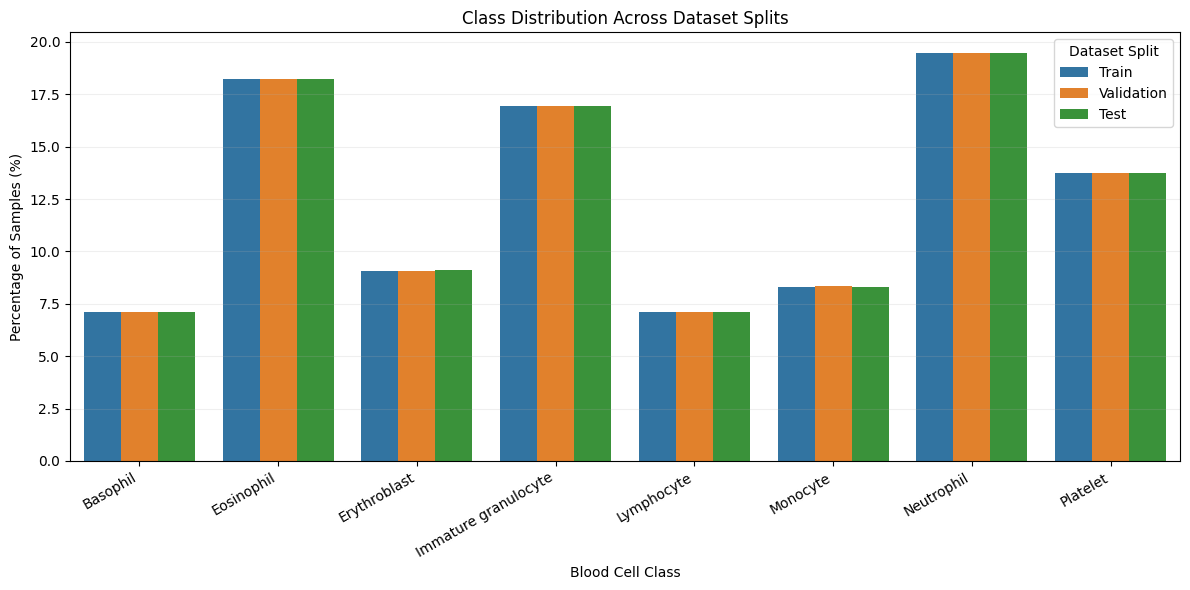

Class distribution chart saved.


In [11]:
# Create shorter display labels for better readability
short_class_names = [
    "Basophil",
    "Eosinophil",
    "Erythroblast",
    "Immature granulocyte",
    "Lymphocyte",
    "Monocyte",
    "Neutrophil",
    "Platelet"
]

# Create a copy for visualisation only
plot_data = class_distribution_df.copy()

# Map original class names to shorter display names
class_name_mapping = dict(zip(class_names, short_class_names))

plot_data["Class"] = plot_data["Class"].map(class_name_mapping)

# Create the grouped bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,
    x="Class",
    y="Percentage",
    hue="Split"
)

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Blood Cell Class")
plt.ylabel("Percentage of Samples (%)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Dataset Split")
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Save the improved figure
plt.savefig(
    "./figures/class_distribution_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Class distribution chart saved.")

## 3.6 Visualisation of Sample Images

Visual inspection helps us understand the appearance and
variation of the blood cell images before model training.

We display representative samples from all eight classes
using images from the training set.

This allows us to examine visual differences between
blood cell categories, including their shape, colour,
and structural characteristics.

The selected images are displayed with their corresponding
class labels. The original dataset images remain unchanged.

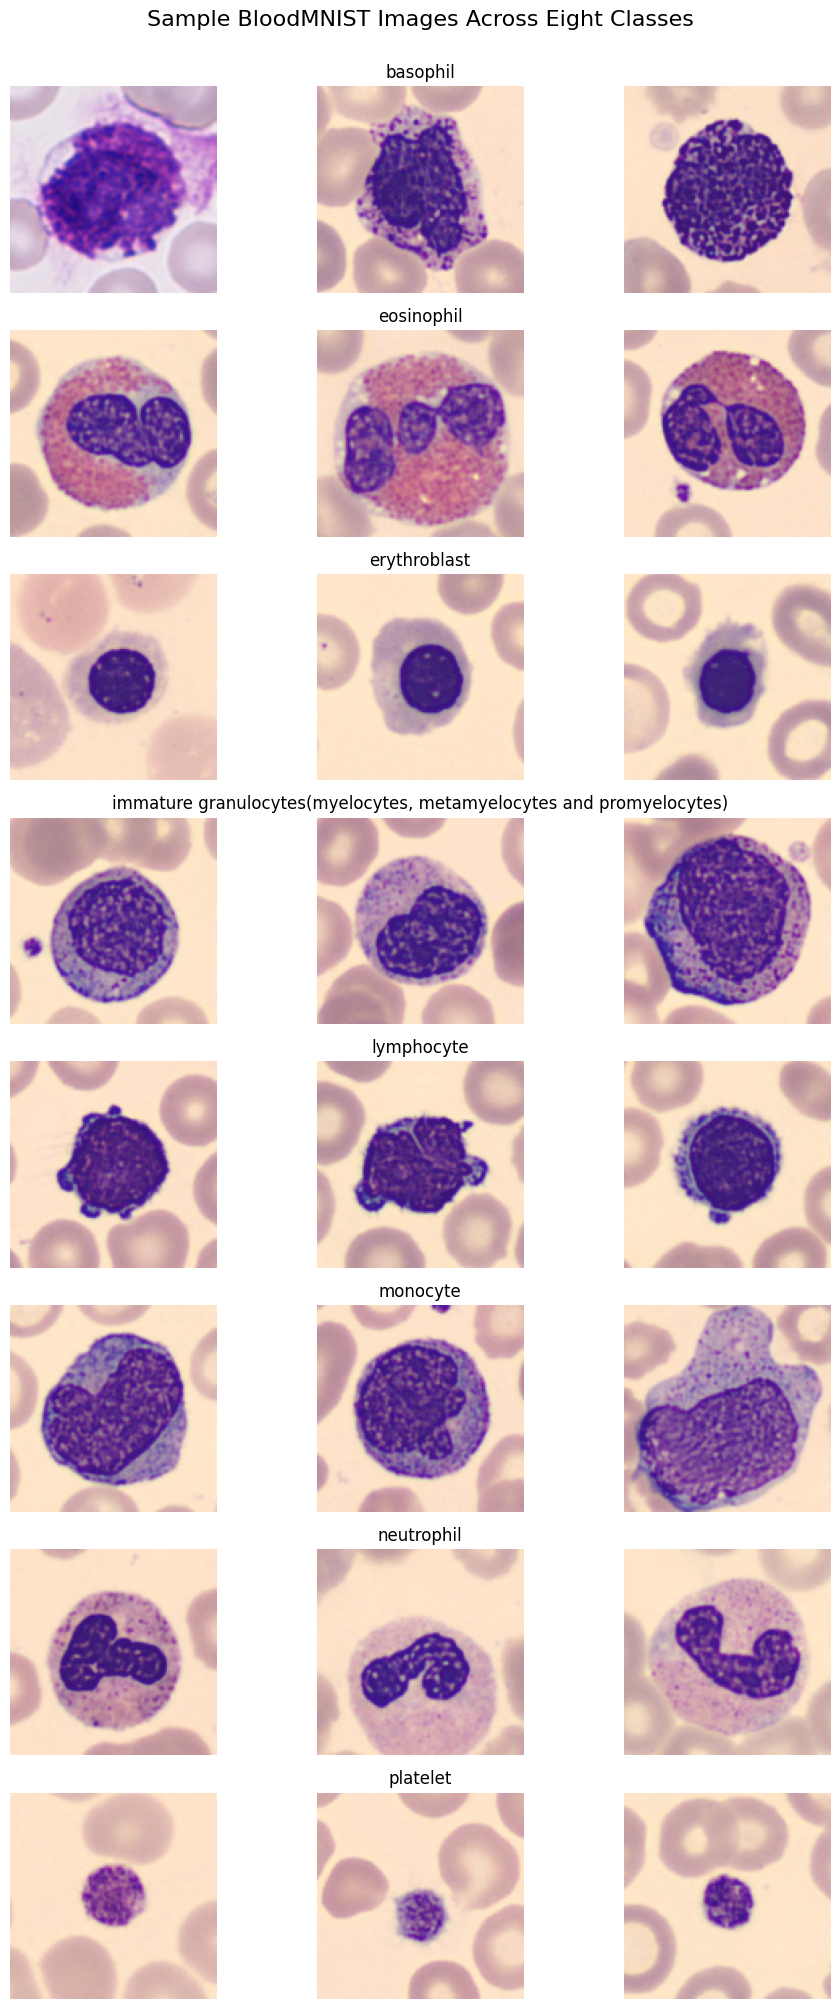

Sample image visualisation saved successfully.


In [12]:
# Define the number of sample images to display per class
SAMPLES_PER_CLASS = 3

# Create a reproducible random number generator for image selection
rng = np.random.default_rng(SEED)

# Flatten training labels for class-based image selection
train_labels_flat = y_train.flatten()

# Create a figure with 8 rows and 3 columns
fig, axes = plt.subplots(
    nrows=len(class_names),
    ncols=SAMPLES_PER_CLASS,
    figsize=(10, 20)
)

# Display randomly selected images from each class
for class_id, class_name in enumerate(class_names):

    # Find the indices of training images belonging to this class
    class_indices = np.where(
        train_labels_flat == class_id
    )[0]

    # Randomly select three images without replacement
    selected_indices = rng.choice(
        class_indices,
        size=min(SAMPLES_PER_CLASS, len(class_indices)),
        replace=False
    )

    # Display the selected images
    for column, image_index in enumerate(selected_indices):

        axes[class_id, column].imshow(X_train[image_index])
        axes[class_id, column].set_title(
            class_name if column == 1 else ""
        )
        axes[class_id, column].axis("off")

# Add an overall figure title
fig.suptitle(
    "Sample BloodMNIST Images Across Eight Classes",
    fontsize=16,
    y=1.002
)

plt.tight_layout()

# Save the visualisation for project documentation
plt.savefig(
    "./figures/bloodmnist_sample_images.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Sample image visualisation saved successfully.")

## 3.7 Dataset Exploration Summary

The initial exploration of BloodMNIST confirmed that the
dataset contains 17,092 RGB images distributed across
eight blood cell categories.

The downloaded 128 × 128 dataset was successfully loaded,
and the official training, validation, and testing splits
were verified.

The image integrity checks confirmed consistent image
dimensions, matching image-label counts, and no missing
or infinite pixel values.

Class distribution analysis revealed differences in the number of samples across categories, with neutrophils being the most represented class, while basophils and lymphocytes had comparatively lower representation in the training set.

Visual inspection of representative images demonstrated
variations in cell morphology, colour, and structure
across the eight categories.

These observations provide an initial understanding of
the dataset and establish the basis for the preprocessing
and model development stages.

# 4. Data Preprocessing and Preparation

This section prepares BloodMNIST images for ResNet-18 training through image transformations, normalization, tensor conversion and DataLoader creation.
### 4.1 Defining Image Transformations

Image preprocessing is an important step in preparing the BloodMNIST dataset for deep learning. The original images have dimensions of 128 × 128 pixels and contain RGB colour information.

In this project, the images will be prepared for the pretrained ResNet-18 architecture using the following transformations:

1. **Resizing:** Images will be resized to 224 × 224 pixels to match the standard input size commonly used with ImageNet-pretrained ResNet-18.
2. **Data augmentation:** Random horizontal flipping, vertical flipping and small rotations will be applied only to training images. These transformations introduce variations and may improve the model's ability to generalise.
3. **Conversion to tensors:** Images will be converted into PyTorch tensors with pixel values scaled to the range [0, 1].
4. **Normalization:** RGB channels will be normalized using the ImageNet mean and standard deviation because ResNet-18 is pretrained on ImageNet.

Separate transformation pipelines will be defined for training and evaluation. Validation and test images will not undergo random augmentation, ensuring consistent and unbiased evaluation.

The official BloodMNIST training, validation and test splits will be preserved throughout the experiments.

In [13]:
# --------------------------------------------------
# 4.1 Defining Image Transformations
# --------------------------------------------------

# ImageNet normalization parameters
# These values correspond to the RGB channels.
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


# Transformations applied to training images
# Random augmentation is used only during training.
train_transform = transforms.Compose([
    transforms.ToPILImage(),                  # Convert NumPy image to PIL format
    transforms.Resize((224, 224)),            # Resize image for ResNet-18
    transforms.RandomHorizontalFlip(p=0.5),   # Random horizontal flip
    transforms.RandomVerticalFlip(p=0.5),     # Random vertical flip
    transforms.RandomRotation(degrees=15),    # Random rotation up to 15 degrees
    transforms.ToTensor(),                    # Convert image to PyTorch tensor
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )                                         # Apply ImageNet normalization
])


# Transformations applied to validation and test images
# No random augmentation is applied during evaluation.
eval_transform = transforms.Compose([
    transforms.ToPILImage(),                  # Convert NumPy image to PIL format
    transforms.Resize((224, 224)),            # Resize image for ResNet-18
    transforms.ToTensor(),                    # Convert image to PyTorch tensor
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )                                         # Apply ImageNet normalization
])


print("Training transformations defined successfully.")
print("Evaluation transformations defined successfully.")

Training transformations defined successfully.
Evaluation transformations defined successfully.


### 4.2 Applying and Verifying Image Preprocessing

The defined transformations will be applied to sample training and evaluation images. Their tensor dimensions and pixel value ranges will be checked to verify that preprocessing works correctly.

In [14]:
# --------------------------------------------------
# 4.2 Applying and Verifying Image Preprocessing
# --------------------------------------------------

# Select one sample image from the training dataset
sample_train_image = X_train[0]

# Select one sample image from the validation dataset
sample_val_image = X_val[0]

# Apply the respective transformations
processed_train_image = train_transform(sample_train_image)
processed_val_image = eval_transform(sample_val_image)

# Display preprocessing results
print("Training image:")
print("Tensor shape:", processed_train_image.shape)
print("Minimum pixel value:", processed_train_image.min().item())
print("Maximum pixel value:", processed_train_image.max().item())

print("\nValidation image:")
print("Tensor shape:", processed_val_image.shape)
print("Minimum pixel value:", processed_val_image.min().item())
print("Maximum pixel value:", processed_val_image.max().item())

# Verify the expected tensor dimensions
assert processed_train_image.shape == (3, 224, 224)
assert processed_val_image.shape == (3, 224, 224)

print("\nImage preprocessing verified successfully.")

Training image:
Tensor shape: torch.Size([3, 224, 224])
Minimum pixel value: -2.1179039478302
Maximum pixel value: 2.248908281326294

Validation image:
Tensor shape: torch.Size([3, 224, 224])
Minimum pixel value: -1.755602240562439
Maximum pixel value: 2.248908281326294

Image preprocessing verified successfully.


### 4.3 Preparing Image Labels

The BloodMNIST labels are stored as two-dimensional arrays. They will be converted into one-dimensional arrays to make them compatible with PyTorch classification workflows.

In [15]:
# --------------------------------------------------
# 4.3 Preparing Image Labels
# --------------------------------------------------

# Flatten the label arrays into one-dimensional arrays
y_train = y_train.reshape(-1)
y_val = y_val.reshape(-1)
y_test = y_test.reshape(-1)

# Convert labels to integer format
y_train = y_train.astype(np.int64)
y_val = y_val.astype(np.int64)
y_test = y_test.astype(np.int64)

# Display dataset and label information
print("Training labels shape:", y_train.shape)
print("Validation labels shape:", y_val.shape)
print("Test labels shape:", y_test.shape)

print("\nNumber of training classes:", len(np.unique(y_train)))
print("Unique training labels:", np.unique(y_train))

# Verify label preparation
assert y_train.ndim == 1
assert y_val.ndim == 1
assert y_test.ndim == 1
assert len(np.unique(y_train)) == 8

print("\nLabel preparation completed successfully.")

Training labels shape: (11959,)
Validation labels shape: (1712,)
Test labels shape: (3421,)

Number of training classes: 8
Unique training labels: [0 1 2 3 4 5 6 7]

Label preparation completed successfully.


### 4.4 Creating PyTorch Dataset Objects

Custom PyTorch Dataset objects will be created for the training, validation and test sets. Each dataset will return a preprocessed image and its corresponding label.

In [16]:
# --------------------------------------------------
# 4.4 Creating PyTorch Dataset Objects
# --------------------------------------------------

from torch.utils.data import Dataset, DataLoader


class BloodMNISTDataset(Dataset):
    """Custom PyTorch dataset for BloodMNIST images."""

    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        # Return the total number of images
        return len(self.images)

    def __getitem__(self, index):
        # Retrieve an image and its corresponding label
        image = self.images[index]
        label = self.labels[index]

        # Apply image transformations when specified
        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)


# Create datasets using the official splits
train_dataset = BloodMNISTDataset(
    X_train, y_train, transform=train_transform
)

val_dataset = BloodMNISTDataset(
    X_val, y_val, transform=eval_transform
)

test_dataset = BloodMNISTDataset(
    X_test, y_test, transform=eval_transform
)


# Verify dataset sizes
print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

# Inspect one training sample
sample_image, sample_label = train_dataset[0]

print("\nSample image shape:", sample_image.shape)
print("Sample label:", sample_label.item())
print("Sample label dtype:", sample_label.dtype)

Training dataset: 11959
Validation dataset: 1712
Test dataset: 3421

Sample image shape: torch.Size([3, 224, 224])
Sample label: 7
Sample label dtype: torch.int64


### 4.5 Creating DataLoaders

PyTorch DataLoaders will organize the datasets into batches for efficient training and evaluation. Shuffling will be enabled only for the training dataset.

In [17]:
# --------------------------------------------------
# 4.5 Creating DataLoaders
# --------------------------------------------------

# Define batch size
BATCH_SIZE = 64

# Use a single process to avoid shared memory issues
NUM_WORKERS = 0

# Create training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# Create validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# Create test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Batch size:", BATCH_SIZE)
print("Number of workers:", NUM_WORKERS)

Training batches: 187
Validation batches: 27
Test batches: 54
Batch size: 64
Number of workers: 0


### 4.6 Verifying DataLoader Batches

A sample batch will be inspected to verify image dimensions, label dimensions and GPU compatibility before model development.

In [18]:
# --------------------------------------------------
# 4.6 Verifying DataLoader Batches
# --------------------------------------------------

# Retrieve one batch from the training DataLoader
images, labels = next(iter(train_loader))

# Display batch properties
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)
print("Current device:", DEVICE)

# Verify batch dimensions
assert images.shape[1:] == (3, 224, 224)
assert labels.ndim == 1
assert images.shape[0] == labels.shape[0]

print("\nDataLoader verification completed successfully.")

Image batch shape: torch.Size([64, 3, 224, 224])
Label batch shape: torch.Size([64])
Image data type: torch.float32
Label data type: torch.int64
Current device: cuda

DataLoader verification completed successfully.


# 5. ResNet-18 Model Development

This section develops ResNet-18 models for multiclass blood cell classification using ImageNet-pretrained weights. Two approaches are investigated: a frozen pretrained backbone and a fine-tuned pretrained backbone.

### 5.1 Introduction to ResNet-18 Architecture

ResNet-18 is a convolutional neural network (CNN) that uses residual connections to improve information and gradient flow during training. It consists of convolutional layers, residual blocks and a final fully connected classification layer.

In this project, ResNet-18 is used with ImageNet-pretrained weights. Its learned features are adapted to classify the eight BloodMNIST blood cell categories.

Two approaches are compared:
- **Frozen backbone:** The pretrained feature extraction layers remain unchanged, while the final classification layer is trained.
- **Fine-tuned backbone:** The pretrained layers and the new classification layer are trained on BloodMNIST.


### 5.2 Loading ImageNet-Pretrained ResNet-18

The ResNet-18 architecture is loaded with weights pretrained on the ImageNet dataset. These weights provide previously learned visual features that can be transferred to the BloodMNIST classification task.

The model is moved to the available computing device (GPU or CPU) for subsequent training.


In [19]:
# Load ResNet-18 with ImageNet-pretrained weights

weights = models.ResNet18_Weights.DEFAULT

pretrained_model = models.resnet18(weights=weights)

# Move the model to the selected device
pretrained_model = pretrained_model.to(DEVICE)

# Display the model architecture
print(pretrained_model)

# Verify the model's final classification layer
print("\nOriginal classification layer:")
print(pretrained_model.fc)

# Display the number of output classes in ImageNet
print("\nOriginal output features:", pretrained_model.fc.out_features)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/jovyan/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 113MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

### 5.3 Understanding the Pretrained Feature Extractor

The pretrained ResNet-18 contains four main residual stages: layer1, layer2, layer3 and layer4. These layers progressively extract visual features, from basic patterns to more complex structures.

The final feature representation contains 512 features, which will be used by a new classification layer for the eight BloodMNIST classes.


In [20]:
# Inspect the main feature extraction layers of ResNet-18

print("Feature extraction layers:")

for name, layer in pretrained_model.named_children():
    if name in ["layer1", "layer2", "layer3", "layer4"]:
        print(f"{name}: {layer}")

# Display the number of input features for the final classifier
print("\nFeatures extracted before classification:",
      pretrained_model.fc.in_features)


Feature extraction layers:
layer1: Sequential(
  (0): BasicBlock(
    (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (1): BasicBlock(
    (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
)
layer2: Sequential(
  (0): BasicBlock(
    (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 

### 5.4 Replacing the Final Classification Layer

The original ResNet-18 classification layer produces 1,000 outputs for ImageNet categories. Since BloodMNIST contains eight blood cell classes, the original fully connected layer is replaced with a new layer containing eight output neurons.

The new layer receives 512 input features extracted by the pretrained backbone.


In [21]:
# Replace the original ImageNet classifier with an 8-class classifier

NUM_CLASSES = 8

pretrained_model.fc = nn.Linear(
    pretrained_model.fc.in_features,
    NUM_CLASSES
)

# Move the updated model to the selected device
pretrained_model = pretrained_model.to(DEVICE)

# Verify the new classification layer
print("Updated classification layer:")
print(pretrained_model.fc)

print("\nNumber of output classes:",
      pretrained_model.fc.out_features)


Updated classification layer:
Linear(in_features=512, out_features=8, bias=True)

Number of output classes: 8


### 5.5 Configuring the Frozen Backbone

In the frozen backbone approach, all pretrained ResNet-18 feature extraction layers are frozen by disabling gradient updates. Only the newly added fully connected classification layer remains trainable.

This allows the model to use ImageNet-learned features while learning a new classifier for the eight BloodMNIST classes.


In [22]:
# Freeze all parameters in the pretrained ResNet-18 model
for param in pretrained_model.parameters():
    param.requires_grad = False

# Enable training only for the new classification layer
for param in pretrained_model.fc.parameters():
    param.requires_grad = True

# Count trainable and total parameters
total_parameters = sum(
    param.numel() for param in pretrained_model.parameters()
)

trainable_parameters = sum(
    param.numel()
    for param in pretrained_model.parameters()
    if param.requires_grad
)

print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)
print("Frozen parameters:", total_parameters - trainable_parameters)

# Verify that only the classification layer is trainable
print("\nTrainable layers:")
for name, param in pretrained_model.named_parameters():
    if param.requires_grad:
        print(name)


Total parameters: 11180616
Trainable parameters: 4104
Frozen parameters: 11176512

Trainable layers:
fc.weight
fc.bias


### 5.6 Configuring the Fine-Tuned Backbone

In the fine-tuning approach, all pretrained ResNet-18 layers, including the new fully connected classification layer, are made trainable.

This allows the model to adjust its pretrained visual features to the BloodMNIST dataset during training.


In [23]:
# Load a separate ResNet-18 model with ImageNet-pretrained weights
finetuned_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Replace the original classifier with an 8-class output layer
finetuned_model.fc = nn.Linear(
    finetuned_model.fc.in_features,
    NUM_CLASSES
)

# Move the model to the selected device
finetuned_model = finetuned_model.to(DEVICE)

# Enable training for all model parameters
for param in finetuned_model.parameters():
    param.requires_grad = True

# Count trainable and total parameters
total_parameters = sum(
    param.numel() for param in finetuned_model.parameters()
)

trainable_parameters = sum(
    param.numel()
    for param in finetuned_model.parameters()
    if param.requires_grad
)

print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)
print("Frozen parameters:", total_parameters - trainable_parameters)


Total parameters: 11180616
Trainable parameters: 11180616
Frozen parameters: 0


### 5.7 Defining Loss Function and Optimisers

Cross-Entropy Loss is used because the task involves multiclass classification with integer class labels.

The AdamW optimiser is selected for model training. It applies adaptive learning rates and decoupled weight decay to help regularise the model.

Separate optimisers are configured:
- Frozen model: updates only the final classification layer.
- Fine-tuned model: updates all trainable model parameters.


In [24]:
# Define the loss function
criterion = nn.CrossEntropyLoss()

# Define the optimiser for the frozen backbone
frozen_optimizer = torch.optim.AdamW(
    pretrained_model.fc.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

# Define the optimiser for the fine-tuned backbone
finetuned_optimizer = torch.optim.AdamW(
    finetuned_model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

# Verify optimiser configurations
print("Loss function:", criterion)

print("\nFrozen model optimiser:")
print(frozen_optimizer)

print("\nFine-tuned model optimiser:")
print(finetuned_optimizer)


Loss function: CrossEntropyLoss()

Frozen model optimiser:
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)

Fine-tuned model optimiser:
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)


### 5.8 Defining Training and Evaluation Functions

Reusable training and evaluation functions are developed to ensure consistent procedures across both experiments.

The training function performs forward propagation, calculates the loss, updates trainable parameters through backpropagation and records training loss and accuracy.

The evaluation function assesses model performance on the validation dataset without updating model parameters. It records validation loss and accuracy.


In [25]:
# Define the training function

def train_one_epoch(
    model, dataloader, criterion, optimizer, device,
    frozen_backbone=False
):

    model.train()

    # Keep Batch Normalization layers fixed for the frozen experiment
    if frozen_backbone:
        model.eval()
        model.fc.train()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for images, labels in dataloader:

        images = images.to(device)
        labels = labels.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Calculate training statistics
        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        correct_predictions += (predictions == labels).sum().item()
        total_samples += labels.size(0)

    epoch_loss = running_loss / total_samples
    epoch_accuracy = correct_predictions / total_samples

    return epoch_loss, epoch_accuracy


# Define the evaluation function

def evaluate_model(model, dataloader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    with torch.no_grad():

        for images, labels in dataloader:

            images = images.to(device)
            labels = labels.to(device)

            # Forward propagation
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Calculate evaluation statistics
            running_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            correct_predictions += (predictions == labels).sum().item()
            total_samples += labels.size(0)

    epoch_loss = running_loss / total_samples
    epoch_accuracy = correct_predictions / total_samples

    return epoch_loss, epoch_accuracy


print("Training and evaluation functions defined successfully.")


Training and evaluation functions defined successfully.


# 6. Model Training and Experiments

This section trains and compares the frozen and fine-tuned pretrained ResNet-18 models using the BloodMNIST dataset. Both approaches use the same official training and validation splits and are evaluated across multiple random seeds to assess consistency.

### 6.1 Defining Experimental Settings

The experimental settings are established to ensure a consistent comparison between the frozen and fine-tuned ResNet-18 models.

Both experiments use a batch size of 64 and are trained for a maximum of 10 epochs. Three random seeds (42, 43 and 44) are used to assess the consistency of model performance.

The official BloodMNIST training split is used for training, while the validation split is used to monitor performance and select the best model checkpoint. The test split remains unused until the final evaluation stage.



In [26]:
# Define experimental settings

BATCH_SIZE = 64
NUM_EPOCHS = 10
RANDOM_SEEDS = [42, 43, 44]

# Define directories for saving model checkpoints and results
CHECKPOINT_DIR = "results/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Display experimental settings
print("Experimental Settings")
print("---------------------")
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", NUM_EPOCHS)
print("Random seeds:", RANDOM_SEEDS)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Computing device:", DEVICE)


Experimental Settings
---------------------
Batch size: 64
Maximum epochs: 10
Random seeds: [42, 43, 44]
Training samples: 11959
Validation samples: 1712
Test samples: 3421
Training batches: 187
Validation batches: 27
Checkpoint directory: results/checkpoints
Computing device: cuda


### 6.2 Experiment 1 – Frozen Pretrained ResNet-18

In this experiment, the ImageNet-pretrained ResNet-18 model is trained with its feature extraction layers frozen. Only the final eight-class classification layer is updated.

The experiment is repeated using three random seeds (42, 43 and 44). Validation loss and accuracy are monitored after each epoch, and the model with the highest validation accuracy is saved for each seed.


In [27]:
# Experiment 1: Frozen pretrained ResNet-18

import copy

frozen_results = {}

for seed in RANDOM_SEEDS:

    print(f"\nStarting frozen experiment with seed {seed}")

    # Set random seeds
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Load a fresh ImageNet-pretrained ResNet-18
    model = models.resnet18(
        weights=models.ResNet18_Weights.DEFAULT
    )

    # Replace the classifier with an 8-class output layer
    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    model = model.to(DEVICE)

    # Freeze the feature extraction layers
    for param in model.parameters():
        param.requires_grad = False

    # Enable training only for the classifier
    for param in model.fc.parameters():
        param.requires_grad = True

    # Define loss and optimiser
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.fc.parameters(),
        lr=0.001,
        weight_decay=0.0001
    )

    # Store training history
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_val_accuracy = 0.0
    best_model_state = None

    # Train the model
    for epoch in range(NUM_EPOCHS):

        train_loss, train_accuracy = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            DEVICE,
            frozen_backbone=True
        )

        val_loss, val_accuracy = evaluate_model(
            model,
            val_loader,
            criterion,
            DEVICE
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"Seed {seed} | Epoch {epoch + 1}/{NUM_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Accuracy: {train_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_accuracy:.4f}"
        )

        # Save the best model based on validation accuracy
        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

    # Save the best checkpoint for this seed
    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"frozen_resnet18_seed_{seed}.pth"
    )

    torch.save(
        {
            "seed": seed,
            "model_state_dict": best_model_state,
            "best_val_accuracy": best_val_accuracy,
            "history": history
        },
        checkpoint_path
    )

    frozen_results[seed] = {
        "history": history,
        "best_val_accuracy": best_val_accuracy,
        "checkpoint": checkpoint_path
    }

    print(
        f"Best validation accuracy for seed {seed}: "
        f"{best_val_accuracy:.4f}"
    )

    print("Checkpoint saved:", checkpoint_path)


print("\nFrozen ResNet-18 experiments completed.")



Starting frozen experiment with seed 42
Seed 42 | Epoch 1/10 | Train Loss: 1.0620 | Train Accuracy: 0.6902 | Val Loss: 0.7680 | Val Accuracy: 0.7436
Seed 42 | Epoch 2/10 | Train Loss: 0.5748 | Train Accuracy: 0.8405 | Val Loss: 0.5757 | Val Accuracy: 0.8084
Seed 42 | Epoch 3/10 | Train Loss: 0.4621 | Train Accuracy: 0.8649 | Val Loss: 0.5121 | Val Accuracy: 0.8236
Seed 42 | Epoch 4/10 | Train Loss: 0.4065 | Train Accuracy: 0.8825 | Val Loss: 0.4415 | Val Accuracy: 0.8499
Seed 42 | Epoch 5/10 | Train Loss: 0.3749 | Train Accuracy: 0.8840 | Val Loss: 0.4180 | Val Accuracy: 0.8586
Seed 42 | Epoch 6/10 | Train Loss: 0.3460 | Train Accuracy: 0.8924 | Val Loss: 0.4037 | Val Accuracy: 0.8569
Seed 42 | Epoch 7/10 | Train Loss: 0.3338 | Train Accuracy: 0.8956 | Val Loss: 0.3703 | Val Accuracy: 0.8697
Seed 42 | Epoch 8/10 | Train Loss: 0.3183 | Train Accuracy: 0.8980 | Val Loss: 0.3738 | Val Accuracy: 0.8657
Seed 42 | Epoch 9/10 | Train Loss: 0.3019 | Train Accuracy: 0.9016 | Val Loss: 0.3796 |

### 6.3 Experiment 2 – Fine-Tuned Pretrained ResNet-18

In this experiment, all layers of the ImageNet-pretrained ResNet-18 model are fine-tuned using the BloodMNIST training dataset. Unlike the frozen approach, the pretrained feature extraction layers are allowed to update their weights during training.

The experiment is repeated using three random seeds (42, 43 and 44). Training and validation performance are monitored for each epoch, and the checkpoint with the highest validation accuracy is saved for each seed.


In [28]:
# Experiment 2: Fine-tuned pretrained ResNet-18

finetuned_results = {}

for seed in RANDOM_SEEDS:

    print(f"\nStarting fine-tuned experiment with seed {seed}")

    # Set random seeds
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Load a fresh ImageNet-pretrained ResNet-18
    model = models.resnet18(
        weights=models.ResNet18_Weights.DEFAULT
    )

    # Replace the original classifier with an 8-class output layer
    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    model = model.to(DEVICE)

    # Enable training for all model parameters
    for param in model.parameters():
        param.requires_grad = True

    # Define loss function and optimiser
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.0001,
        weight_decay=0.0001
    )

    # Store training history
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_val_accuracy = 0.0
    best_model_state = None

    # Train the model
    for epoch in range(NUM_EPOCHS):

        train_loss, train_accuracy = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            DEVICE,
            frozen_backbone=False
        )

        val_loss, val_accuracy = evaluate_model(
            model,
            val_loader,
            criterion,
            DEVICE
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"Seed {seed} | Epoch {epoch + 1}/{NUM_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Accuracy: {train_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_accuracy:.4f}"
        )

        # Save the best model based on validation accuracy
        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

    # Save the best checkpoint for this seed
    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"finetuned_resnet18_seed_{seed}.pth"
    )

    torch.save(
        {
            "seed": seed,
            "model_state_dict": best_model_state,
            "best_val_accuracy": best_val_accuracy,
            "history": history
        },
        checkpoint_path
    )

    finetuned_results[seed] = {
        "history": history,
        "best_val_accuracy": best_val_accuracy,
        "checkpoint": checkpoint_path
    }

    print(
        f"Best validation accuracy for seed {seed}: "
        f"{best_val_accuracy:.4f}"
    )

    print("Checkpoint saved:", checkpoint_path)


print("\nFine-tuned ResNet-18 experiments completed.")



Starting fine-tuned experiment with seed 42
Seed 42 | Epoch 1/10 | Train Loss: 0.1888 | Train Accuracy: 0.9407 | Val Loss: 0.1014 | Val Accuracy: 0.9591
Seed 42 | Epoch 2/10 | Train Loss: 0.0522 | Train Accuracy: 0.9833 | Val Loss: 0.0650 | Val Accuracy: 0.9755
Seed 42 | Epoch 3/10 | Train Loss: 0.0466 | Train Accuracy: 0.9847 | Val Loss: 0.0302 | Val Accuracy: 0.9912
Seed 42 | Epoch 4/10 | Train Loss: 0.0392 | Train Accuracy: 0.9856 | Val Loss: 0.0320 | Val Accuracy: 0.9895
Seed 42 | Epoch 5/10 | Train Loss: 0.0344 | Train Accuracy: 0.9882 | Val Loss: 0.0321 | Val Accuracy: 0.9877
Seed 42 | Epoch 6/10 | Train Loss: 0.0294 | Train Accuracy: 0.9902 | Val Loss: 0.0356 | Val Accuracy: 0.9895
Seed 42 | Epoch 7/10 | Train Loss: 0.0252 | Train Accuracy: 0.9910 | Val Loss: 0.0334 | Val Accuracy: 0.9883
Seed 42 | Epoch 8/10 | Train Loss: 0.0228 | Train Accuracy: 0.9920 | Val Loss: 0.0251 | Val Accuracy: 0.9907
Seed 42 | Epoch 9/10 | Train Loss: 0.0185 | Train Accuracy: 0.9932 | Val Loss: 0.03

## 6.4 Training Using Multiple Random Seeds

Three random seeds (42, 43 and 44) were used to evaluate the consistency and reproducibility of both frozen and fine-tuned ResNet-18 models. The mean and standard deviation of the best validation accuracies were calculated across the three runs to compare model performance and variability.

In [29]:
# Calculate best validation accuracy across the three random seeds

frozen_accuracies = [
    frozen_results[seed]["best_val_accuracy"]
    for seed in RANDOM_SEEDS
]

finetuned_accuracies = [
    finetuned_results[seed]["best_val_accuracy"]
    for seed in RANDOM_SEEDS
]

# Calculate mean and sample standard deviation
frozen_mean = np.mean(frozen_accuracies)
frozen_std = np.std(frozen_accuracies, ddof=1)

finetuned_mean = np.mean(finetuned_accuracies)
finetuned_std = np.std(finetuned_accuracies, ddof=1)

# Display comparison
print("MULTI-SEED VALIDATION RESULTS")
print("-" * 45)

print(f"Frozen ResNet-18:    {frozen_mean * 100:.2f}% "
      f"+/- {frozen_std * 100:.2f}%")

print(f"Fine-tuned ResNet-18: {finetuned_mean * 100:.2f}% "
      f"+/- {finetuned_std * 100:.2f}%")

print(f"\nImprovement: {(finetuned_mean - frozen_mean) * 100:.2f} percentage points")

MULTI-SEED VALIDATION RESULTS
---------------------------------------------
Frozen ResNet-18:    88.45% +/- 0.85%
Fine-tuned ResNet-18: 99.12% +/- 0.06%

Improvement: 10.67 percentage points


## 6.5 Monitoring Training and Validation Performance

Training and validation loss and accuracy were monitored over 10 epochs for each random seed. The performance of both frozen and fine-tuned ResNet-18 models was recorded to observe learning progress and generalisation. The best model checkpoint for each run was selected based on validation accuracy.

In [30]:
# Display the best validation accuracy for each seed and experiment

print("FROZEN RESNET-18")
for seed in RANDOM_SEEDS:
    print(f"Seed {seed}: "
          f"{frozen_results[seed]['best_val_accuracy'] * 100:.2f}%")

print("\nFINE-TUNED RESNET-18")
for seed in RANDOM_SEEDS:
    print(f"Seed {seed}: "
          f"{finetuned_results[seed]['best_val_accuracy'] * 100:.2f}%")

FROZEN RESNET-18
Seed 42: 87.50%
Seed 43: 88.73%
Seed 44: 89.14%

FINE-TUNED RESNET-18
Seed 42: 99.12%
Seed 43: 99.07%
Seed 44: 99.18%


## 6.6 Plotting Training and Validation Loss Curves

Training and validation loss curves were plotted across 10 epochs for each random seed. These curves help visualise the learning progress of the frozen and fine-tuned ResNet-18 models and identify changes in model convergence and generalisation during training.

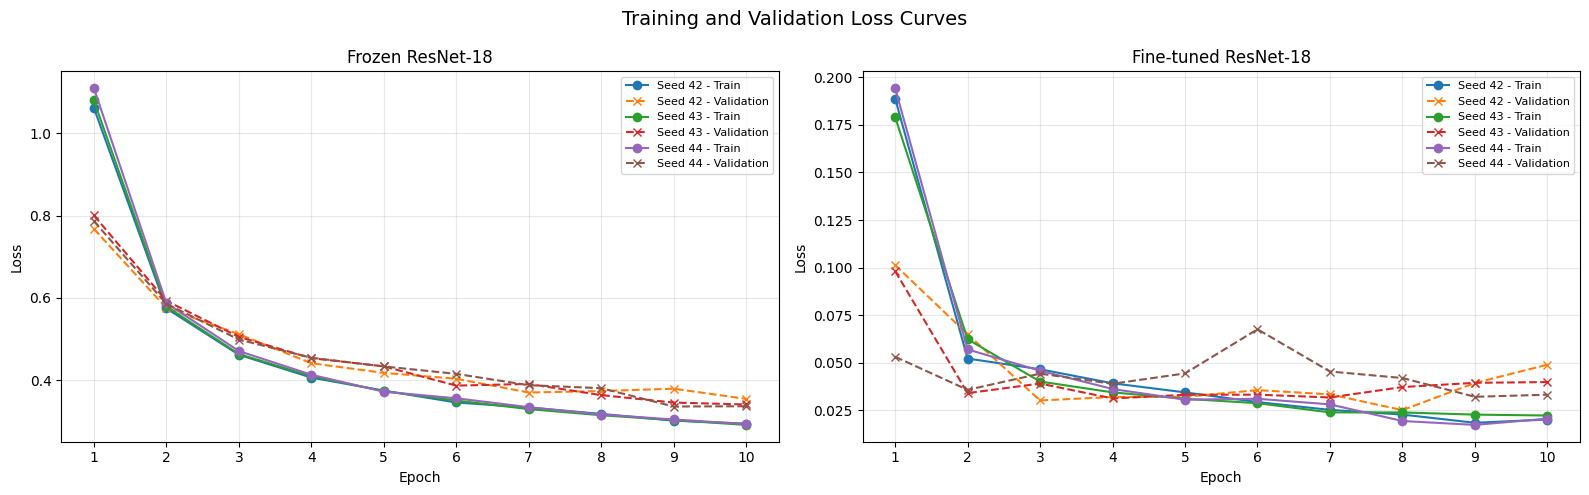

Loss curves saved successfully.


In [31]:
# Plot training and validation loss curves for both experiments

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

experiments = [
    (frozen_results, "Frozen ResNet-18"),
    (finetuned_results, "Fine-tuned ResNet-18")
]

for ax, (results, experiment_name) in zip(axes, experiments):

    for seed in RANDOM_SEEDS:
        history = results[seed]["history"]
        epochs = range(1, len(history["train_loss"]) + 1)

        # Training loss
        ax.plot(
            epochs,
            history["train_loss"],
            marker="o",
            label=f"Seed {seed} - Train"
        )

        # Validation loss
        ax.plot(
            epochs,
            history["val_loss"],
            marker="x",
            linestyle="--",
            label=f"Seed {seed} - Validation"
        )

    ax.set_title(experiment_name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_xticks(range(1, NUM_EPOCHS + 1))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle("Training and Validation Loss Curves", fontsize=14)
plt.tight_layout()

# Save the figure
plt.savefig("figures/loss_curves_comparison.png", dpi=300, bbox_inches="tight")

plt.show()

print("Loss curves saved successfully.")

The loss curves show that both models learned successfully over the training period. However, the fine-tuned ResNet-18 achieved substantially lower training and validation losses, indicating more effective adaptation to the BloodMNIST dataset. Some fluctuations in validation loss were observed across epochs, particularly for Seed 44, highlighting variations in generalisation performance.

## 6.7 Saving Best Model Checkpoints and Training Histories

The best model checkpoint from each training run was saved based on validation accuracy. Training histories were also exported as CSV files to preserve epoch-wise training and validation loss and accuracy. These files support reproducibility and further model evaluation.

In [32]:
# Save training histories and verify all model checkpoints

import os

os.makedirs("results/checkpoints", exist_ok=True)
os.makedirs("results/histories", exist_ok=True)

# Combine both experiments
all_results = {
    "frozen": frozen_results,
    "finetuned": finetuned_results
}

for experiment_name, experiment_results in all_results.items():

    for seed, result in experiment_results.items():

        # Save epoch-wise training history as CSV
        history_df = pd.DataFrame(result["history"])

        history_path = (
            f"results/histories/{experiment_name}_seed_{seed}_history.csv"
        )

        history_df.to_csv(history_path, index=False)

        # Verify checkpoint exists
        checkpoint_path = result["checkpoint"]

        if os.path.exists(checkpoint_path):
            print(f"Checkpoint verified: {checkpoint_path}")
        else:
            print(f"WARNING: Checkpoint not found: {checkpoint_path}")

        print(f"History saved: {history_path}")

print("\nAll training histories exported.")

Checkpoint verified: results/checkpoints/frozen_resnet18_seed_42.pth
History saved: results/histories/frozen_seed_42_history.csv
Checkpoint verified: results/checkpoints/frozen_resnet18_seed_43.pth
History saved: results/histories/frozen_seed_43_history.csv
Checkpoint verified: results/checkpoints/frozen_resnet18_seed_44.pth
History saved: results/histories/frozen_seed_44_history.csv
Checkpoint verified: results/checkpoints/finetuned_resnet18_seed_42.pth
History saved: results/histories/finetuned_seed_42_history.csv
Checkpoint verified: results/checkpoints/finetuned_resnet18_seed_43.pth
History saved: results/histories/finetuned_seed_43_history.csv
Checkpoint verified: results/checkpoints/finetuned_resnet18_seed_44.pth
History saved: results/histories/finetuned_seed_44_history.csv

All training histories exported.


# 7. Model Evaluation

This section evaluates the frozen and fine-tuned ResNet-18 models using the independent BloodMNIST test dataset. Performance is assessed using accuracy, precision, recall, F1-score, classification reports and confusion matrices. Results across the three random seeds are compared to examine model performance and consistency.

## 7.1 Loading the Best Saved Model Checkpoints

The best checkpoints selected based on validation accuracy are loaded for each random seed. Both frozen and fine-tuned ResNet-18 models are restored from their saved state dictionaries and prepared for evaluation on the independent test dataset.

In [33]:
# Define the class names
CLASS_NAMES = [
    "Basophil",
    "Eosinophil",
    "Erythroblast",
    "Immature Granulocytes",
    "Lymphocyte",
    "Monocyte",
    "Neutrophil",
    "Platelet"
]

# Function to load a saved ResNet-18 checkpoint
def load_resnet_checkpoint(checkpoint_path):

    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, len(CLASS_NAMES))

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(DEVICE)
    model.eval()

    return model

print("Checkpoint loading function defined successfully.")

Checkpoint loading function defined successfully.


In [34]:
# Load frozen and fine-tuned ResNet-18 models for all three seeds

frozen_models = {}
finetuned_models = {}

for seed in RANDOM_SEEDS:

    # Load frozen model
    frozen_path = f"results/checkpoints/frozen_resnet18_seed_{seed}.pth"
    frozen_models[seed] = load_resnet_checkpoint(frozen_path)

    # Load fine-tuned model
    finetuned_path = f"results/checkpoints/finetuned_resnet18_seed_{seed}.pth"
    finetuned_models[seed] = load_resnet_checkpoint(finetuned_path)

print("All six models loaded successfully.")
print("Frozen models:", list(frozen_models.keys()))
print("Fine-tuned models:", list(finetuned_models.keys()))
print("Evaluation device:", DEVICE)

All six models loaded successfully.
Frozen models: [42, 43, 44]
Fine-tuned models: [42, 43, 44]
Evaluation device: cuda


## 7.2 Evaluating on the Independent Test Set

All six trained models are evaluated using the independent BloodMNIST test dataset containing 3,421 images. The test dataset is used only for final performance evaluation and was not involved in model training or checkpoint selection. Predictions and true labels are collected for calculating evaluation metrics.

In [35]:
# Evaluate all six models on the independent test dataset

def get_predictions(model, dataloader, device):
    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in tqdm(dataloader):
            images = images.to(device)

            outputs = model(images)
            predictions = torch.argmax(outputs, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    return np.array(all_labels), np.array(all_predictions)


# Store predictions and true labels for each experiment and seed
test_results = {
    "frozen": {},
    "finetuned": {}
}

for experiment_name, models_dict in [
    ("frozen", frozen_models),
    ("finetuned", finetuned_models)
]:

    for seed, model in models_dict.items():

        print(f"\nEvaluating {experiment_name} model - Seed {seed}")

        y_true, y_pred = get_predictions(
            model, test_loader, DEVICE
        )

        test_results[experiment_name][seed] = {
            "y_true": y_true,
            "y_pred": y_pred
        }

        print(f"Test samples evaluated: {len(y_true)}")
        print(f"Accuracy: {accuracy_score(y_true, y_pred) * 100:.2f}%")

print("\nEvaluation of all six models completed.")


Evaluating frozen model - Seed 42


  0%|          | 0/54 [00:00<?, ?it/s]

Test samples evaluated: 3421
Accuracy: 88.75%

Evaluating frozen model - Seed 43


  0%|          | 0/54 [00:00<?, ?it/s]

Test samples evaluated: 3421
Accuracy: 89.07%

Evaluating frozen model - Seed 44


  0%|          | 0/54 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/54 [00:00<?, ?it/s]

Test samples evaluated: 3421
Accuracy: 98.80%

Evaluating finetuned model - Seed 44


  0%|          | 0/54 [00:00<?, ?it/s]

Test samples evaluated: 3421
Accuracy: 98.98%

Evaluation of all six models completed.


## 7.3 Accuracy, Precision, Recall and F1-Score

Accuracy, precision, recall and macro-averaged F1-score are calculated for each model and random seed using the independent test dataset. These metrics provide an overall comparison of classification performance across the eight blood cell classes.

In [36]:
# Calculate evaluation metrics for all six models

metric_results = []

for experiment_name in ["frozen", "finetuned"]:
    for seed in RANDOM_SEEDS:

        y_true = test_results[experiment_name][seed]["y_true"]
        y_pred = test_results[experiment_name][seed]["y_pred"]

        accuracy = accuracy_score(y_true, y_pred)
        precision = precision_score(
            y_true, y_pred, average="macro", zero_division=0
        )
        recall = recall_score(
            y_true, y_pred, average="macro", zero_division=0
        )
        f1 = f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )

        metric_results.append({
            "Model": experiment_name.capitalize(),
            "Seed": seed,
            "Accuracy (%)": accuracy * 100,
            "Precision (%)": precision * 100,
            "Recall (%)": recall * 100,
            "F1-Score (%)": f1 * 100
        })

metrics_df = pd.DataFrame(metric_results)

print("MODEL PERFORMANCE COMPARISON")
display(metrics_df.round(2))

# Calculate mean and standard deviation across seeds
summary_df = metrics_df.groupby("Model").agg({
    "Accuracy (%)": ["mean", "std"],
    "Precision (%)": ["mean", "std"],
    "Recall (%)": ["mean", "std"],
    "F1-Score (%)": ["mean", "std"]
})

print("\nMEAN AND STANDARD DEVIATION ACROSS THREE SEEDS")
display(summary_df.round(2))


MODEL PERFORMANCE COMPARISON


,Model,Seed,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Frozen,42,88.75,90.13,87.29,88.42
1,Frozen,43,89.07,89.06,87.86,88.29
2,Frozen,44,89.27,90.60,87.27,88.60
3,Finetuned,42,98.63,98.70,98.76,98.73
4,Finetuned,43,98.80,98.97,98.77,98.87
5,Finetuned,44,98.98,99.03,99.06,99.04



MEAN AND STANDARD DEVIATION ACROSS THREE SEEDS


Accuracy (%)       Precision (%)       Recall (%)        \
                  mean   std          mean   std       mean   std   
Model                                                               
Finetuned        98.80  0.18         98.90  0.17      98.86  0.17   
Frozen           89.03  0.27         89.93  0.79      87.48  0.33   

          F1-Score (%)        
                  mean   std  
Model                         
Finetuned        98.88  0.15  
Frozen           88.44  0.15

### Interpretation of Evaluation Metrics

The fine-tuned ResNet-18 model outperformed the frozen ResNet-18 model across all evaluation metrics. It achieved a mean test accuracy of 98.80% and a macro F1-score of 98.88%, compared with 89.03% and 88.44%, respectively, for the frozen model.

The results indicate that fine-tuning the pretrained backbone enabled better adaptation to the BloodMNIST dataset. The low standard deviations across the three random seeds also suggest consistent performance. Further class-wise analysis is required to identify specific classification errors and commonly confused blood cell types.

## 7.4 Classification Reports

Classification reports are generated for each model and random seed to examine class-wise precision, recall and F1-score. These reports provide detailed insights into the classification performance of individual blood cell types and help identify classes that are more difficult to classify.

In [37]:
# Generate classification reports for all six models

classification_reports = {
    "frozen": {},
    "finetuned": {}
}

for experiment_name in ["frozen", "finetuned"]:

    for seed in RANDOM_SEEDS:

        print("\n" + "=" * 65)
        print(f"{experiment_name.upper()} RESNET-18 - SEED {seed}")
        print("=" * 65)

        y_true = test_results[experiment_name][seed]["y_true"]
        y_pred = test_results[experiment_name][seed]["y_pred"]

        report = classification_report(
            y_true,
            y_pred,
            target_names=CLASS_NAMES,
            zero_division=0,
            output_dict=True
        )

        classification_reports[experiment_name][seed] = report

        print(classification_report(
            y_true,
            y_pred,
            target_names=CLASS_NAMES,
            zero_division=0
        ))

print("\nAll classification reports generated successfully.")


FROZEN RESNET-18 - SEED 42
                       precision    recall  f1-score   support

             Basophil       0.93      0.76      0.84       244
           Eosinophil       0.95      0.89      0.92       624
         Erythroblast       0.94      0.86      0.89       311
Immature Granulocytes       0.79      0.83      0.81       579
           Lymphocyte       0.90      0.93      0.91       243
             Monocyte       0.91      0.77      0.84       284
           Neutrophil       0.83      0.97      0.89       666
             Platelet       0.96      0.98      0.97       470

             accuracy                           0.89      3421
            macro avg       0.90      0.87      0.88      3421
         weighted avg       0.89      0.89      0.89      3421


FROZEN RESNET-18 - SEED 43
                       precision    recall  f1-score   support

             Basophil       0.92      0.76      0.83       244
           Eosinophil       0.91      0.95      0.93      

## 7.5 Confusion Matrices

Confusion matrices are generated to examine the classification performance of each model across the eight blood cell classes. They show the number of correctly and incorrectly classified images, helping identify commonly confused blood cell types. The matrices are compared between frozen and fine-tuned ResNet-18 models.

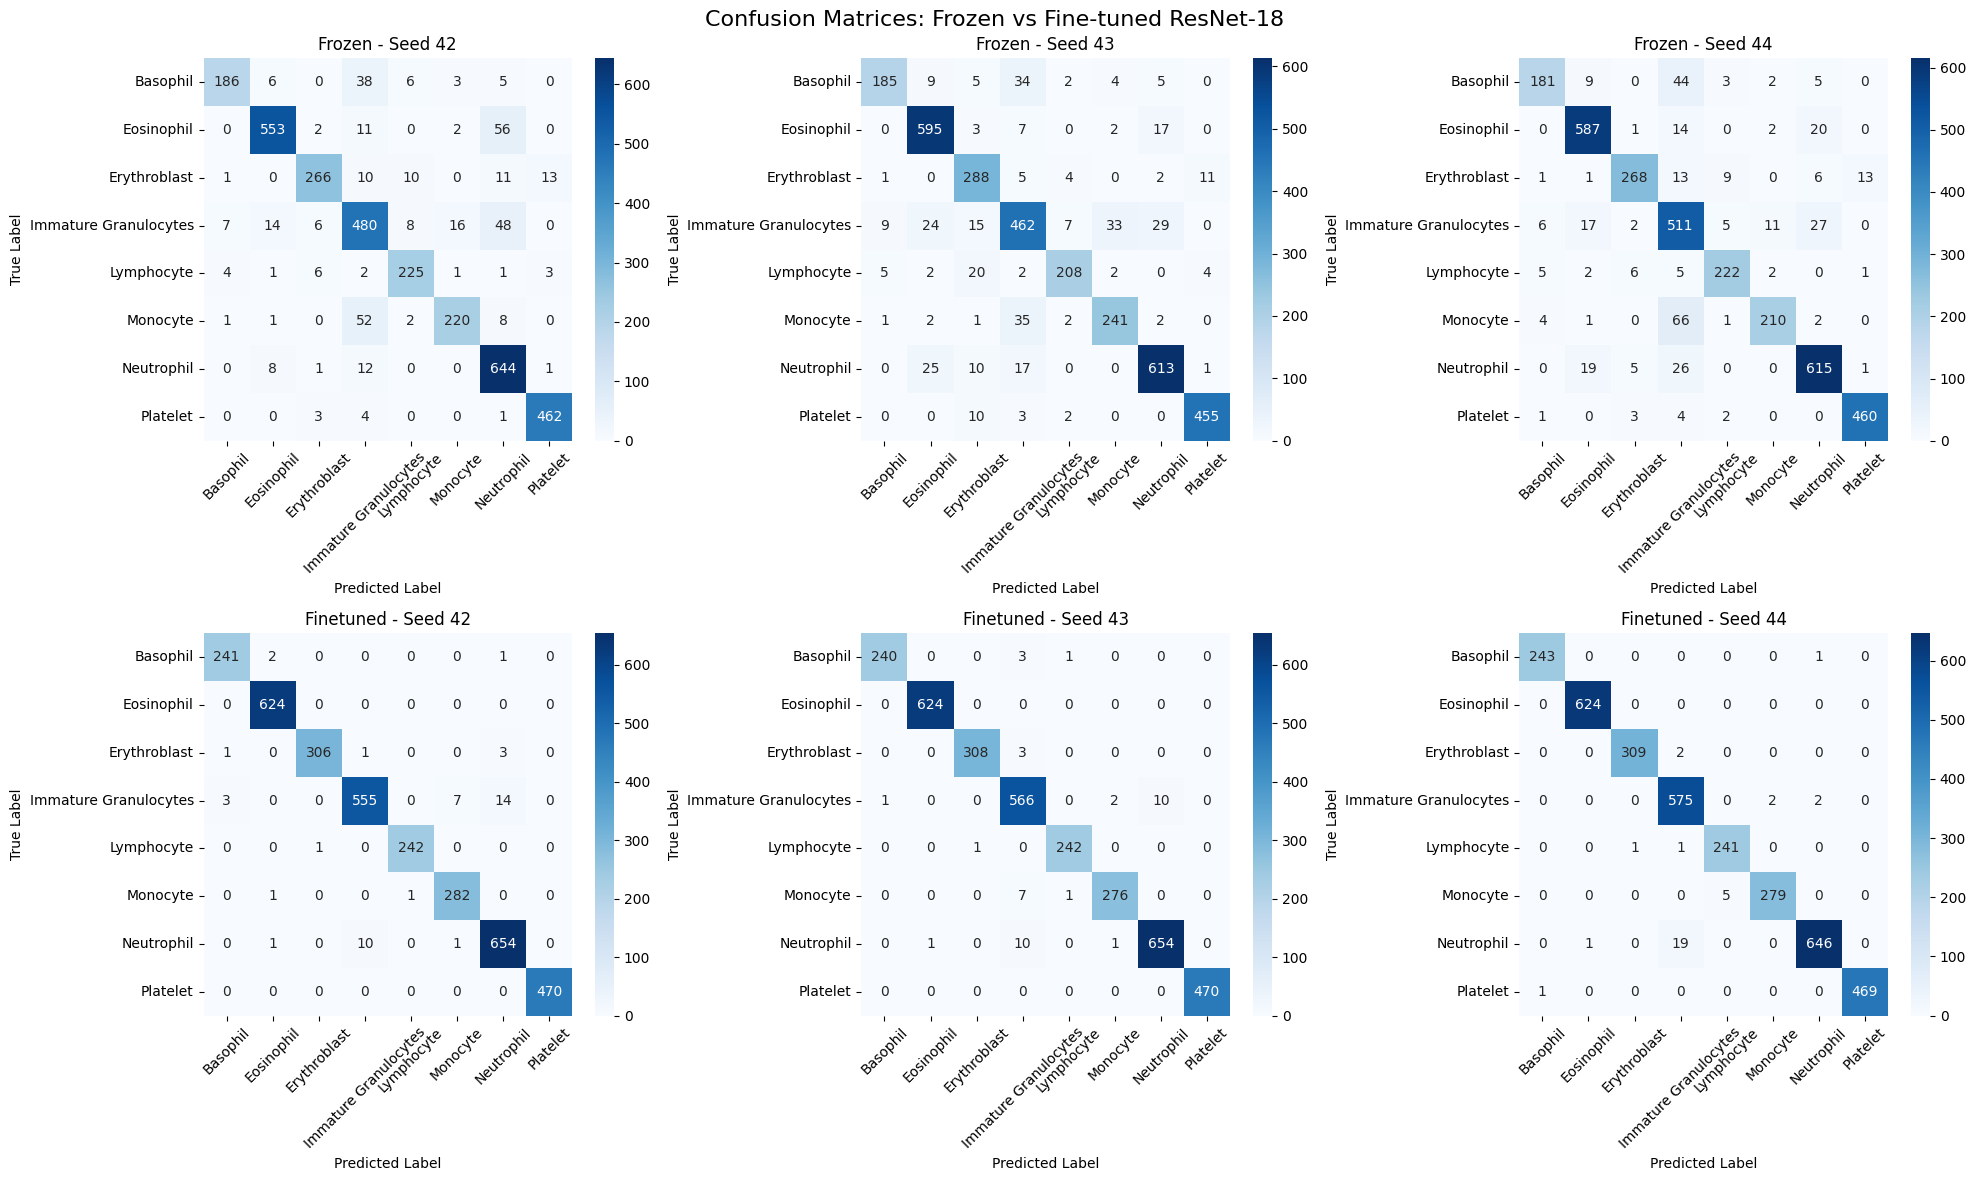

Confusion matrices saved successfully.


In [38]:
# Generate confusion matrices for all six models

fig, axes = plt.subplots(2, 3, figsize=(20, 12))

for row, experiment_name in enumerate(["frozen", "finetuned"]):

    for col, seed in enumerate(RANDOM_SEEDS):

        y_true = test_results[experiment_name][seed]["y_true"]
        y_pred = test_results[experiment_name][seed]["y_pred"]

        cm = confusion_matrix(
            y_true, y_pred, labels=range(len(CLASS_NAMES))
        )

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES,
            ax=axes[row, col]
        )

        axes[row, col].set_title(
            f"{experiment_name.capitalize()} - Seed {seed}"
        )
        axes[row, col].set_xlabel("Predicted Label")
        axes[row, col].set_ylabel("True Label")

        axes[row, col].tick_params(axis="x", rotation=45)
        axes[row, col].tick_params(axis="y", rotation=0)

plt.suptitle("Confusion Matrices: Frozen vs Fine-tuned ResNet-18",
             fontsize=16)
plt.tight_layout()

plt.savefig(
    "figures/confusion_matrices_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrices saved successfully.")

## 7.6 Class-wise Performance Analysis

Class-wise precision, recall and F1-scores are compared between frozen and fine-tuned ResNet-18 models. The results across all three random seeds are used to examine performance differences for each blood cell category and identify classes with comparatively lower classification performance.

In [39]:
# Calculate class-wise metrics averaged across three random seeds

class_metrics = []

for experiment_name in ["frozen", "finetuned"]:

    for seed in RANDOM_SEEDS:

        y_true = test_results[experiment_name][seed]["y_true"]
        y_pred = test_results[experiment_name][seed]["y_pred"]

        report = classification_reports[experiment_name][seed]

        for class_name in CLASS_NAMES:

            class_metrics.append({
                "Model": experiment_name.capitalize(),
                "Seed": seed,
                "Class": class_name,
                "Precision": report[class_name]["precision"],
                "Recall": report[class_name]["recall"],
                "F1-score": report[class_name]["f1-score"]
            })

class_metrics_df = pd.DataFrame(class_metrics)

# Calculate mean class-wise performance across seeds
class_summary = (
    class_metrics_df
    .groupby(["Model", "Class"])[["Precision", "Recall", "F1-score"]]
    .mean()
    .reset_index()
)

print("MEAN CLASS-WISE PERFORMANCE ACROSS THREE SEEDS")
display(class_summary.round(4))

MEAN CLASS-WISE PERFORMANCE ACROSS THREE SEEDS


,Model,Class,Precision,Recall,F1-score
0,Finetuned,Basophil,0.9918,0.9891,0.9904
1,Finetuned,Eosinophil,0.9968,1.0000,0.9984
2,Finetuned,Erythroblast,0.9968,0.9893,0.9930
3,Finetuned,Immature Granulocytes,0.9682,0.9764,0.9722
4,Finetuned,Lymphocyte,0.9891,0.9945,0.9918
5,Finetuned,Monocyte,0.9848,0.9824,0.9836
6,Finetuned,Neutrophil,0.9845,0.9780,0.9812
7,Finetuned,Platelet,1.0000,0.9993,0.9996
8,Frozen,Basophil,0.9231,0.7541,0.8301
9,Frozen,Eosinophil,0.9257,0.9268,0.9257


### Interpretation of Class-wise Performance

The class-wise evaluation demonstrates that fine-tuning improved classification performance across all eight blood cell categories. The largest improvements were observed for basophils, immature granulocytes and monocytes. Platelets and eosinophils achieved the highest F1-scores in the fine-tuned model, while immature granulocytes remained the most challenging class.

These findings indicate that fine-tuning improved the model's ability to distinguish between different blood cell types, including classes that were more difficult to classify using the frozen pretrained backbone.

## 7.7 Summary of Results Across Multiple Seeds

The evaluation metrics from all three random seeds are summarised to compare the overall performance and consistency of frozen and fine-tuned ResNet-18 models. Mean and standard deviation values are used to report performance across repeated training runs.

In [40]:
# Summarise test performance across three random seeds

final_summary = metrics_df.groupby("Model").agg({
    "Accuracy (%)": ["mean", "std"],
    "Precision (%)": ["mean", "std"],
    "Recall (%)": ["mean", "std"],
    "F1-Score (%)": ["mean", "std"]
})

print("FINAL TEST PERFORMANCE SUMMARY")
display(final_summary.round(2))

# Save summary to CSV
final_summary.to_csv("results/final_test_performance_summary.csv")

print("\nFinal performance summary saved successfully.")

FINAL TEST PERFORMANCE SUMMARY


Accuracy (%)       Precision (%)       Recall (%)        \
                  mean   std          mean   std       mean   std   
Model                                                               
Finetuned        98.80  0.18         98.90  0.17      98.86  0.17   
Frozen           89.03  0.27         89.93  0.79      87.48  0.33   

          F1-Score (%)        
                  mean   std  
Model                         
Finetuned        98.88  0.15  
Frozen           88.44  0.15


Final performance summary saved successfully.


## 7.8 Statistical Analysis Using Bootstrap Confidence Intervals

Bootstrap resampling is used to estimate 95% confidence intervals for test accuracy and macro F1-score using 2,000 resamples. A paired comparison is also performed to estimate the performance difference between frozen and fine-tuned ResNet-18 models across the three random seeds.

In [41]:
# Bootstrap confidence intervals and paired model comparison

from sklearn.metrics import accuracy_score, f1_score

N_BOOTSTRAPS = 2000
CONFIDENCE_LEVEL = 95
rng = np.random.default_rng(42)

# Verify that all models use the same test labels
y_true_reference = test_results["frozen"][RANDOM_SEEDS[0]]["y_true"]
n_samples = len(y_true_reference)

for experiment in ["frozen", "finetuned"]:
    for seed in RANDOM_SEEDS:
        assert np.array_equal(
            test_results[experiment][seed]["y_true"],
            y_true_reference
        ), "Test labels differ between model runs."

# Store bootstrap results
bootstrap_scores = {
    "frozen": {"accuracy": [], "macro_f1": []},
    "finetuned": {"accuracy": [], "macro_f1": []}
}

bootstrap_differences = {
    "accuracy": [],
    "macro_f1": []
}

# Perform paired bootstrap resampling
for _ in range(N_BOOTSTRAPS):

    # Sample test indices with replacement
    indices = rng.integers(0, n_samples, size=n_samples)
    y_boot = y_true_reference[indices]

    seed_scores = {
        "frozen": {"accuracy": [], "macro_f1": []},
        "finetuned": {"accuracy": [], "macro_f1": []}
    }

    for experiment in ["frozen", "finetuned"]:
        for seed in RANDOM_SEEDS:

            y_pred = test_results[experiment][seed]["y_pred"][indices]

            seed_scores[experiment]["accuracy"].append(
                accuracy_score(y_boot, y_pred)
            )

            seed_scores[experiment]["macro_f1"].append(
                f1_score(
                    y_boot,
                    y_pred,
                    labels=np.arange(len(CLASS_NAMES)),
                    average="macro",
                    zero_division=0
                )
            )

    # Average performance across the three seeds
    for experiment in ["frozen", "finetuned"]:
        for metric in ["accuracy", "macro_f1"]:
            bootstrap_scores[experiment][metric].append(
                np.mean(seed_scores[experiment][metric])
            )

    # Paired difference: fine-tuned minus frozen
    for metric in ["accuracy", "macro_f1"]:
        difference = (
            np.mean(seed_scores["finetuned"][metric])
            - np.mean(seed_scores["frozen"][metric])
        )
        bootstrap_differences[metric].append(difference)


# Calculate percentile confidence intervals
lower_percentile = (100 - CONFIDENCE_LEVEL) / 2
upper_percentile = 100 - lower_percentile

results = []

for metric in ["accuracy", "macro_f1"]:

    for experiment in ["frozen", "finetuned"]:

        values = np.array(bootstrap_scores[experiment][metric])

        results.append({
            "Metric": metric,
            "Model": experiment.capitalize(),
            "Mean (%)": values.mean() * 100,
            "95% CI Lower (%)": np.percentile(values, lower_percentile) * 100,
            "95% CI Upper (%)": np.percentile(values, upper_percentile) * 100
        })

    # Confidence interval for paired performance difference
    differences = np.array(bootstrap_differences[metric])

    results.append({
        "Metric": metric,
        "Model": "Fine-tuned - Frozen",
        "Mean (%)": differences.mean() * 100,
        "95% CI Lower (%)": np.percentile(differences, lower_percentile) * 100,
        "95% CI Upper (%)": np.percentile(differences, upper_percentile) * 100
    })

bootstrap_summary = pd.DataFrame(results)

print(f"BOOTSTRAP RESULTS ({N_BOOTSTRAPS} RESAMPLES)")
display(bootstrap_summary.round(2))

print("\nINTERPRETATION OF PAIRED DIFFERENCES")

for metric in ["accuracy", "macro_f1"]:

    differences = np.array(bootstrap_differences[metric])
    lower = np.percentile(differences, lower_percentile) * 100
    upper = np.percentile(differences, upper_percentile) * 100

    if lower > 0:
        conclusion = "Fine-tuned model shows a positive improvement."
    elif upper < 0:
        conclusion = "Frozen model shows a positive improvement."
    else:
        conclusion = "The confidence interval includes zero."

    print(
        f"{metric}: 95% CI for improvement = "
        f"[{lower:.2f}, {upper:.2f}] percentage points. "
        f"{conclusion}"
    )

# Save bootstrap results
bootstrap_summary.to_csv(
    "results/bootstrap_confidence_intervals.csv",
    index=False
)

print("\nBootstrap results saved successfully.")

BOOTSTRAP RESULTS (2000 RESAMPLES)


,Metric,Model,Mean (%),95% CI Lower (%),95% CI Upper (%)
0,accuracy,Frozen,89.04,88.08,89.97
1,accuracy,Finetuned,98.81,98.49,99.09
2,accuracy,Fine-tuned - Frozen,9.77,8.85,10.72
3,macro_f1,Frozen,88.44,87.39,89.49
4,macro_f1,Finetuned,98.88,98.58,99.16
5,macro_f1,Fine-tuned - Frozen,10.44,9.43,11.50



INTERPRETATION OF PAIRED DIFFERENCES
accuracy: 95% CI for improvement = [8.85, 10.72] percentage points. Fine-tuned model shows a positive improvement.
macro_f1: 95% CI for improvement = [9.43, 11.50] percentage points. Fine-tuned model shows a positive improvement.

Bootstrap results saved successfully.


**Interpretation:**

The bootstrap analysis demonstrated that fine-tuned ResNet-18 outperformed the frozen model in both accuracy and macro F1-score. The estimated improvement was 9.77 percentage points in accuracy (95% CI: 8.85–10.72) and 10.44 percentage points in macro F1-score (95% CI: 9.43–11.50).

As both confidence intervals exclude zero, the results provide strong evidence of improved test performance with fine-tuning. These findings are consistent with the results observed across the three random seeds.

# 8. Explainability and Error Analysis

This section investigates the decision-making behaviour of the fine-tuned ResNet-18 model using Gradient-weighted Class Activation Mapping (Grad-CAM). Correctly and incorrectly classified test images are examined to understand the image regions influencing model predictions and identify potential classification errors or visual shortcuts.
## 8.1 Understanding Grad-CAM

Grad-CAM (Gradient-weighted Class Activation Mapping) is a visual explanation technique used to highlight image regions that contribute to a model's prediction. It uses gradients flowing into the final convolutional layer to generate a heatmap showing areas that have a strong influence on the predicted class.

In this project, Grad-CAM is used to examine whether the fine-tuned ResNet-18 model focuses on relevant blood cell structures when classifying BloodMNIST images.

## 8.2 Implementing Grad-CAM for ResNet-18

Grad-CAM is implemented using the final convolutional layer (layer4) of ResNet-18. Forward and backward hooks are used to capture feature activations and their corresponding gradients. These are combined to generate a class-specific heatmap highlighting image regions that influence the model's prediction.

In [42]:
# Import required libraries
import torch.nn.functional as F

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        # Register forward hook to capture feature activations
        self.forward_hook = target_layer.register_forward_hook(
            self.save_activations
        )

        # Register full backward hook to capture gradients
        self.backward_hook = target_layer.register_full_backward_hook(
            self.save_gradients
        )

    def save_activations(self, module, input, output):
        self.activations = output.detach()

    def save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, image, class_idx=None):

        self.model.eval()
        self.model.zero_grad(set_to_none=True)

        # Forward pass
        output = self.model(image)

        # Use predicted class if no class is specified
        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        # Backward pass for the selected class
        score = output[:, class_idx]
        score.backward()

        # Calculate channel-wise importance weights
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)

        # Generate Grad-CAM heatmap
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)

        # Resize heatmap to input image dimensions
        cam = F.interpolate(
            cam,
            size=image.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        # Normalize heatmap between 0 and 1
        cam_min = cam.amin(dim=(2, 3), keepdim=True)
        cam_max = cam.amax(dim=(2, 3), keepdim=True)

        cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)

        return cam.squeeze().cpu().numpy(), class_idx

    def remove_hooks(self):
        self.forward_hook.remove()
        self.backward_hook.remove()


# Load fine-tuned model using seed 42
gradcam_model = finetuned_models[42]

# Select the final convolutional block
target_layer = gradcam_model.layer4[-1]

# Initialize Grad-CAM
gradcam = GradCAM(gradcam_model, target_layer)

print("Grad-CAM implementation initialized successfully.")
print("Target layer:", target_layer)

Grad-CAM implementation initialized successfully.
Target layer: BasicBlock(
  (conv1): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)


## 8.3 Visualising Correctly Classified Images

Grad-CAM heatmaps are generated for correctly classified test images using the fine-tuned ResNet-18 model. The heatmaps are overlaid on the original images to highlight regions that contribute to the model's predictions.

Number of correctly classified images: 3374


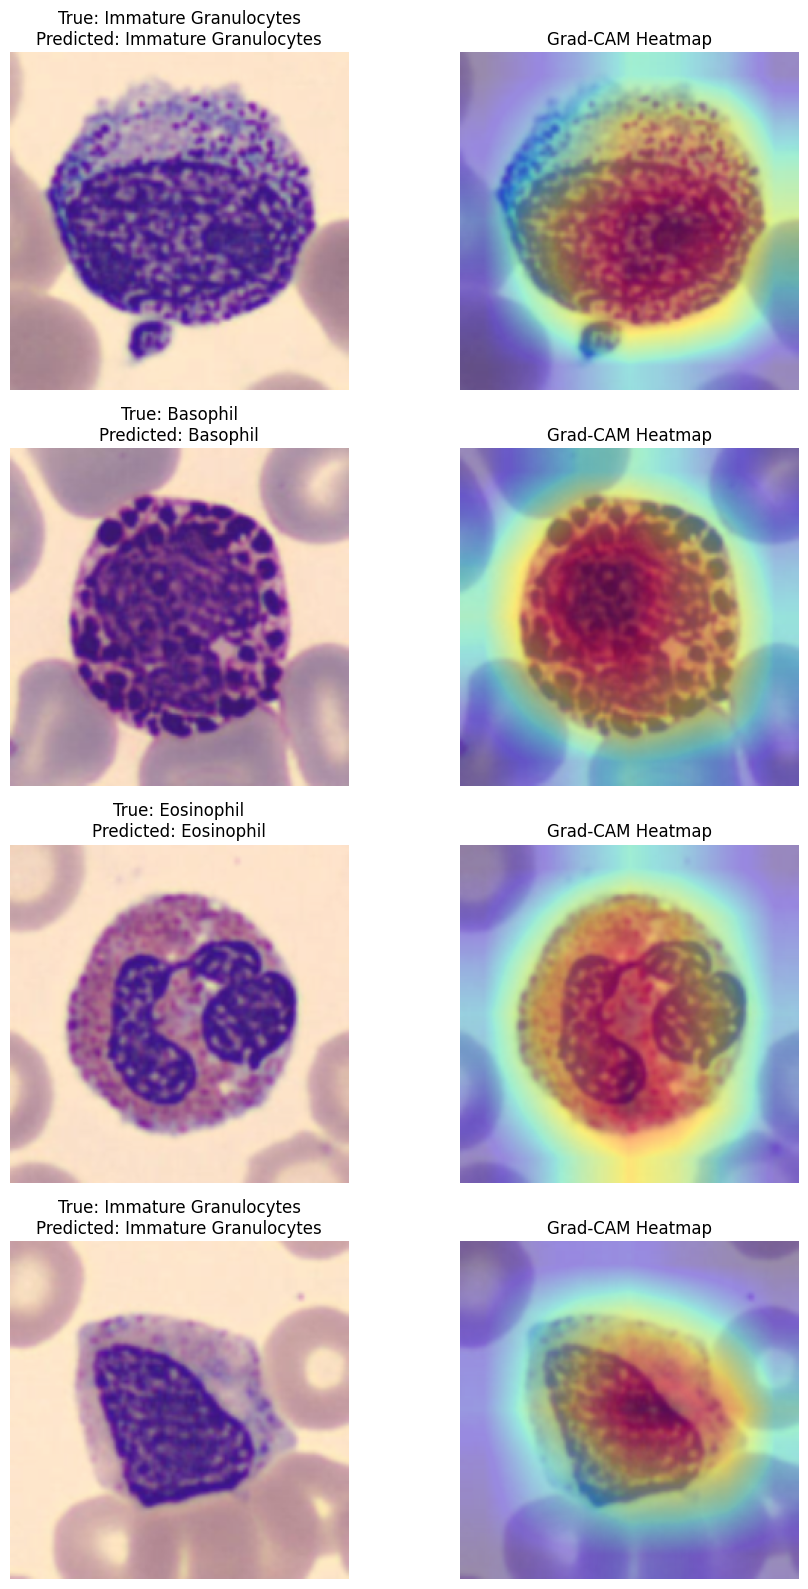

Correct prediction Grad-CAM visualisation completed.


In [43]:
# Find correctly classified test images for fine-tuned Seed 42

y_true = test_results["finetuned"][42]["y_true"]
y_pred = test_results["finetuned"][42]["y_pred"]

correct_indices = np.where(y_true == y_pred)[0]

print("Number of correctly classified images:", len(correct_indices))

# Select up to 4 correctly classified images
selected_correct = correct_indices[:4]

# Visualise Grad-CAM heatmaps
fig, axes = plt.subplots(len(selected_correct), 2, figsize=(10, 4 * len(selected_correct)))

for row, idx in enumerate(selected_correct):

    image_tensor, true_label = test_dataset[idx]
    input_tensor = image_tensor.unsqueeze(0).to(DEVICE)

    # Generate Grad-CAM
    heatmap, predicted_class = gradcam.generate(input_tensor)

    # Convert normalized image back to RGB
    image = image_tensor.permute(1, 2, 0).numpy()
    image = image * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    image = np.clip(image, 0, 1)

    # Original image
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"True: {CLASS_NAMES[true_label]}\nPredicted: {CLASS_NAMES[predicted_class]}")
    axes[row, 0].axis("off")

    # Grad-CAM overlay
    axes[row, 1].imshow(image)
    axes[row, 1].imshow(heatmap, cmap="jet", alpha=0.4)
    axes[row, 1].set_title("Grad-CAM Heatmap")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.savefig("figures/gradcam_correct_predictions.png", dpi=300, bbox_inches="tight")
plt.show()

print("Correct prediction Grad-CAM visualisation completed.")

## 8.4 Visualising Incorrectly Classified Images

Grad-CAM heatmaps are generated for incorrectly classified test images using the fine-tuned ResNet-18 model. The visualisations compare the true and predicted classes and highlight image regions that influenced the incorrect predictions. This analysis helps investigate potential reasons for classification errors.

Number of incorrectly classified images: 47


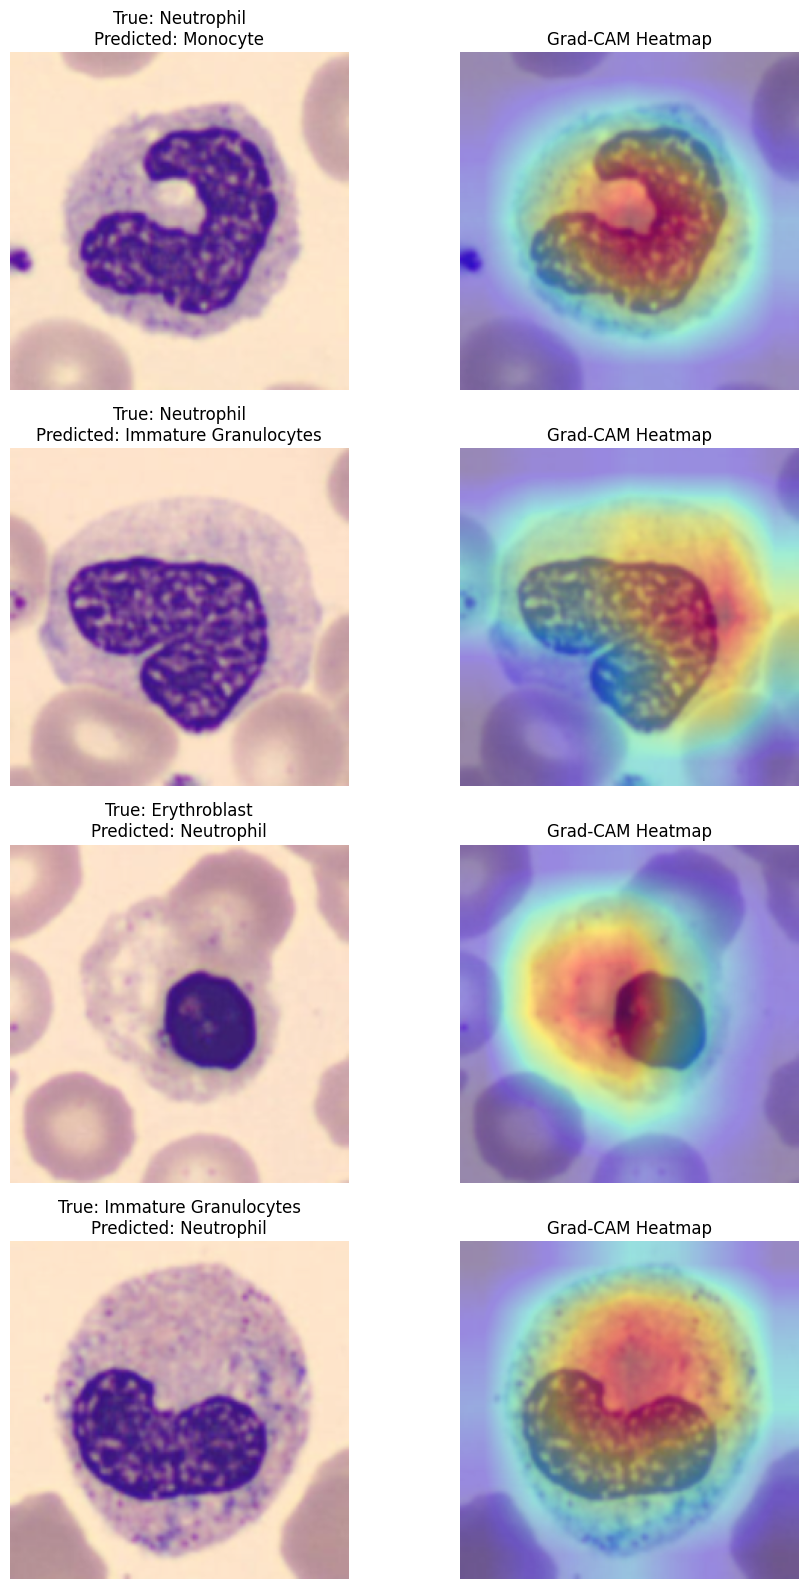

Incorrect prediction Grad-CAM visualisation completed.


In [44]:
# Find incorrectly classified test images for fine-tuned Seed 42

y_true = test_results["finetuned"][42]["y_true"]
y_pred = test_results["finetuned"][42]["y_pred"]

incorrect_indices = np.where(y_true != y_pred)[0]

print("Number of incorrectly classified images:", len(incorrect_indices))

# Select up to 4 incorrectly classified images
selected_incorrect = incorrect_indices[:4]

if len(selected_incorrect) == 0:
    print("No incorrectly classified images found.")
else:
    fig, axes = plt.subplots(
        len(selected_incorrect), 2,
        figsize=(10, 4 * len(selected_incorrect))
    )

    if len(selected_incorrect) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, idx in enumerate(selected_incorrect):

        image_tensor, true_label = test_dataset[idx]
        input_tensor = image_tensor.unsqueeze(0).to(DEVICE)

        # Generate Grad-CAM for the predicted class
        heatmap, predicted_class = gradcam.generate(input_tensor)

        # Convert normalized image back to RGB
        image = image_tensor.permute(1, 2, 0).numpy()
        image = image * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
        image = np.clip(image, 0, 1)

        # Display original image
        axes[row, 0].imshow(image)
        axes[row, 0].set_title(
            f"True: {CLASS_NAMES[true_label]}\n"
            f"Predicted: {CLASS_NAMES[predicted_class]}"
        )
        axes[row, 0].axis("off")

        # Display Grad-CAM overlay
        axes[row, 1].imshow(image)
        axes[row, 1].imshow(heatmap, cmap="jet", alpha=0.4)
        axes[row, 1].set_title("Grad-CAM Heatmap")
        axes[row, 1].axis("off")

    plt.tight_layout()

    plt.savefig(
        "figures/gradcam_incorrect_predictions.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Incorrect prediction Grad-CAM visualisation completed.")

## 8.5 Identifying Commonly Confused Blood Cell Classes

Misclassification patterns are analysed using the confusion matrices from all three random seeds. The analysis identifies frequently confused blood cell categories and examines whether similar classification errors occur consistently across different training runs.

In [45]:
# Identify the most frequent misclassification pairs
# using all three seeds of the fine-tuned model

error_counts = np.zeros(
    (len(CLASS_NAMES), len(CLASS_NAMES)), dtype=int
)

for seed in RANDOM_SEEDS:

    y_true = test_results["finetuned"][seed]["y_true"]
    y_pred = test_results["finetuned"][seed]["y_pred"]

    cm = confusion_matrix(
        y_true, y_pred, labels=range(len(CLASS_NAMES))
    )

    # Remove correct predictions from the diagonal
    cm_off_diagonal = cm.copy()
    np.fill_diagonal(cm_off_diagonal, 0)

    error_counts += cm_off_diagonal

# Extract and sort misclassification pairs
error_pairs = []

for true_idx in range(len(CLASS_NAMES)):
    for pred_idx in range(len(CLASS_NAMES)):

        count = error_counts[true_idx, pred_idx]

        if count > 0:
            error_pairs.append({
                "True Class": CLASS_NAMES[true_idx],
                "Predicted Class": CLASS_NAMES[pred_idx],
                "Total Errors Across Seeds": count
            })

error_pairs_df = pd.DataFrame(error_pairs)

error_pairs_df = error_pairs_df.sort_values(
    "Total Errors Across Seeds", ascending=False
).reset_index(drop=True)

print("MOST FREQUENT MISCLASSIFICATION PAIRS")
display(error_pairs_df.head(10))

MOST FREQUENT MISCLASSIFICATION PAIRS


,True Class,Predicted Class,Total Errors Across Seeds
0,Neutrophil,Immature Granulocytes,39
1,Immature Granulocytes,Neutrophil,26
2,Immature Granulocytes,Monocyte,11
3,Monocyte,Immature Granulocytes,7
4,Monocyte,Lymphocyte,7
5,Erythroblast,Immature Granulocytes,6
6,Immature Granulocytes,Basophil,4
7,Lymphocyte,Erythroblast,3
8,Neutrophil,Eosinophil,3
9,Basophil,Immature Granulocytes,3


### Interpretation of Commonly Confused Blood Cell Classes

The misclassification analysis reveals that neutrophils and immature granulocytes are the most frequently confused blood cell categories. Neutrophils were incorrectly classified as immature granulocytes 39 times, while immature granulocytes were classified as neutrophils 26 times across the three random seeds.

Other errors involved immature granulocytes and monocytes. These findings suggest that similarities in cellular morphology may contribute to classification difficulties. Despite the high overall test accuracy, distinguishing between certain visually similar blood cell categories remains challenging.

## 8.6 Aggregated Confusion Matrix Across Three Random Seeds

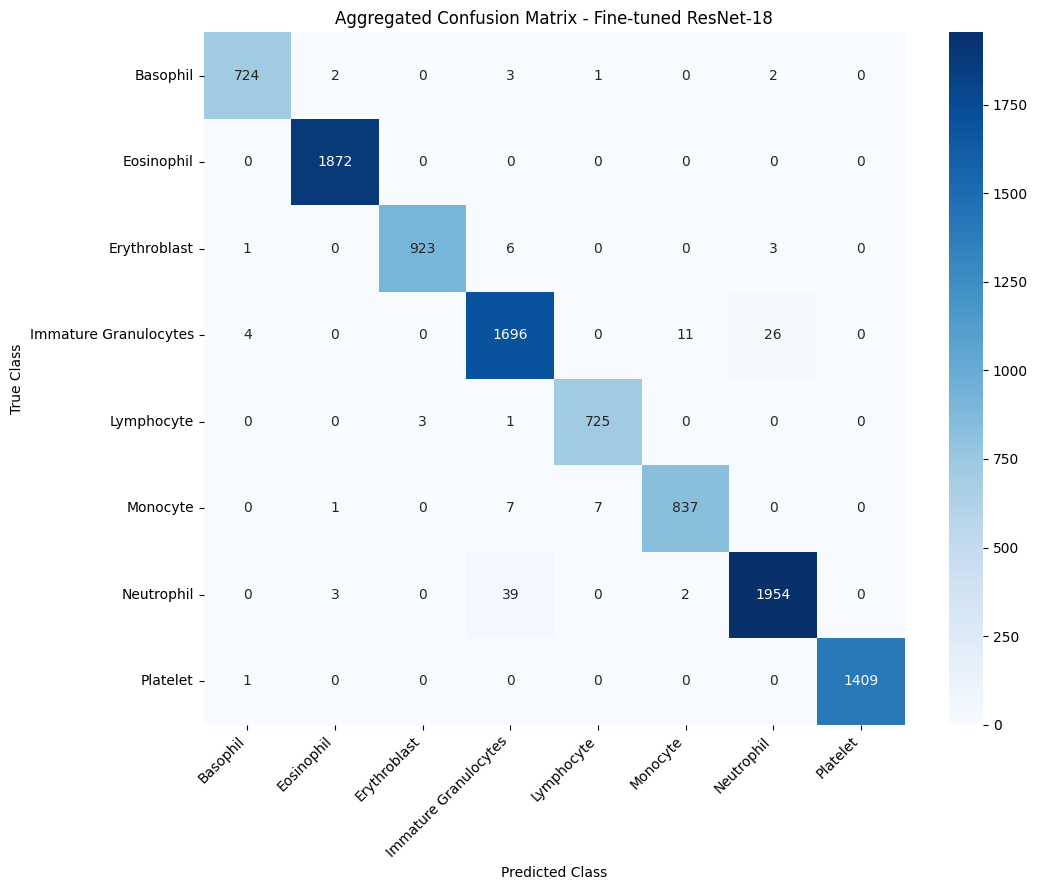

Aggregated confusion matrix generated successfully.


In [46]:
# Generate aggregated confusion matrix for fine-tuned ResNet-18

aggregated_cm = np.zeros(
    (len(CLASS_NAMES), len(CLASS_NAMES)),
    dtype=int
)

for seed in RANDOM_SEEDS:

    y_true = test_results["finetuned"][seed]["y_true"]
    y_pred = test_results["finetuned"][seed]["y_pred"]

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=range(len(CLASS_NAMES))
    )

    aggregated_cm += cm

# Plot aggregated confusion matrix
plt.figure(figsize=(11, 9))

sns.heatmap(
    aggregated_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Aggregated Confusion Matrix - Fine-tuned ResNet-18")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "figures/aggregated_finetuned_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Aggregated confusion matrix generated successfully.")

### Interpretation of the Aggregated Confusion Matrix

The aggregated confusion matrix shows that the fine-tuned ResNet-18 model correctly classified the majority of test images across all eight blood cell categories. Most values are concentrated along the diagonal, indicating strong classification performance.

The most noticeable misclassification pattern occurs between neutrophils and immature granulocytes. Across the three random seeds, 39 neutrophils were predicted as immature granulocytes, while 26 immature granulocytes were predicted as neutrophils. Additional errors were observed between immature granulocytes and monocytes.

These findings are consistent with the class-wise evaluation and suggest that distinguishing between neutrophils and immature granulocytes remains a challenging aspect of the classification task.

## 8.7 Interpreting Model Attention and Possible Shortcuts

Grad-CAM visualisations are examined to understand whether the model focuses on relevant blood cell structures or potentially relies on irrelevant background information. A random-weight sanity check is performed by comparing the Grad-CAM heatmap of the trained model with that of a randomly initialised ResNet-18 model. If the heatmaps differ, this provides evidence that the visual explanations depend on the learned model parameters.

### Grad-CAM Random-Weight Sanity Check

A randomly initialised ResNet-18 model is used to generate a Grad-CAM heatmap for the same test image and target class as the trained model. The resulting heatmaps are compared visually to examine whether the trained model's attention patterns depend on learned weights.

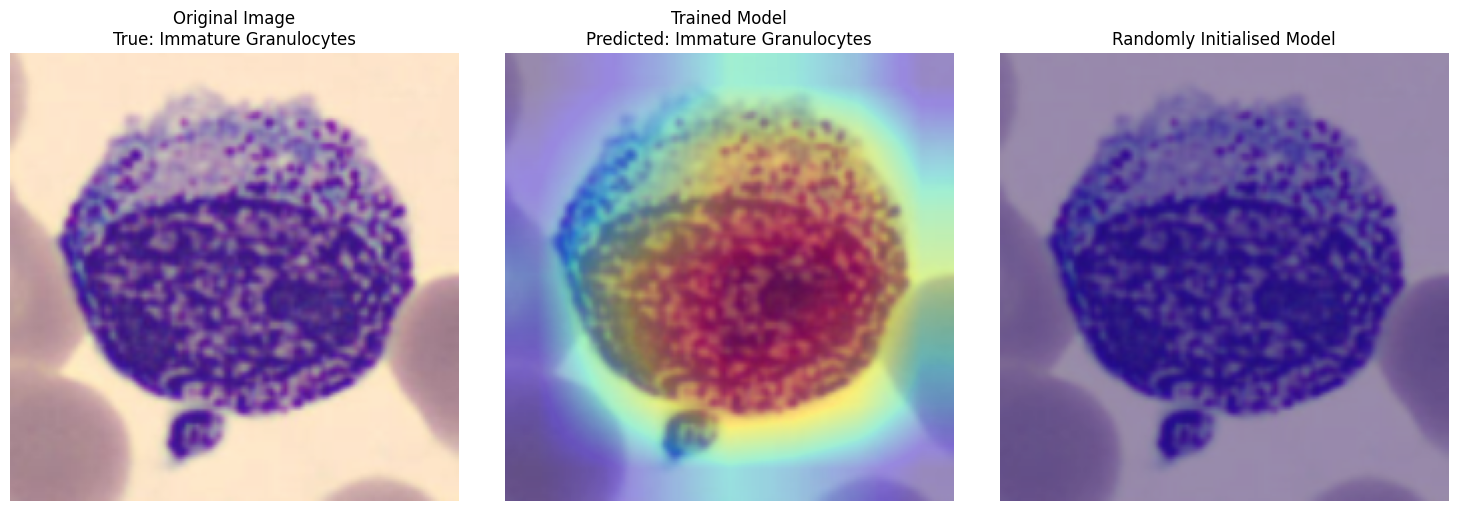

Mean absolute heatmap difference: 0.4587
Grad-CAM sanity check completed.


In [47]:
# Select one test image for the sanity check
sample_idx = int(correct_indices[0])

image_tensor, true_label = test_dataset[sample_idx]
input_tensor = image_tensor.unsqueeze(0).to(DEVICE)

# Get the trained model's prediction
trained_model = finetuned_models[42]
trained_model.eval()

with torch.no_grad():
    trained_output = trained_model(input_tensor)
    trained_prediction = trained_output.argmax(dim=1).item()

# Recreate Grad-CAM for the trained model
trained_gradcam = GradCAM(
    trained_model,
    trained_model.layer4[-1]
)

trained_heatmap, _ = trained_gradcam.generate(
    input_tensor, class_idx=trained_prediction
)

# Create a randomly initialised ResNet-18
random_model = models.resnet18(weights=None)
random_model.fc = nn.Linear(
    random_model.fc.in_features, len(CLASS_NAMES)
)
random_model = random_model.to(DEVICE)
random_model.eval()

# Generate Grad-CAM using random weights
random_gradcam = GradCAM(
    random_model,
    random_model.layer4[-1]
)

random_heatmap, _ = random_gradcam.generate(
    input_tensor, class_idx=trained_prediction
)

# Convert image back to RGB
image = image_tensor.permute(1, 2, 0).numpy()
image = image * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
image = np.clip(image, 0, 1)

# Compare the heatmaps
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title(
    f"Original Image\nTrue: {CLASS_NAMES[true_label]}"
)
axes[0].axis("off")

axes[1].imshow(image)
axes[1].imshow(trained_heatmap, cmap="jet", alpha=0.4)
axes[1].set_title(
    f"Trained Model\nPredicted: {CLASS_NAMES[trained_prediction]}"
)
axes[1].axis("off")

axes[2].imshow(image)
axes[2].imshow(random_heatmap, cmap="jet", alpha=0.4)
axes[2].set_title("Randomly Initialised Model")
axes[2].axis("off")

plt.tight_layout()
plt.savefig(
    "figures/gradcam_random_weight_sanity_check.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Calculate numerical difference between heatmaps
heatmap_difference = np.mean(
    np.abs(trained_heatmap - random_heatmap)
)

print(f"Mean absolute heatmap difference: {heatmap_difference:.4f}")

# Remove hooks
trained_gradcam.remove_hooks()
random_gradcam.remove_hooks()

print("Grad-CAM sanity check completed.")

### Interpretation of Grad-CAM Sanity Check

The Grad-CAM sanity check produced different heatmaps for the trained and randomly initialised ResNet-18 models, with a mean absolute heatmap difference of 0.4587. The trained model showed stronger activation around the blood cell structure, whereas the randomly initialised model produced a different attention pattern.

This observation suggests that the Grad-CAM visualisation is influenced by the learned model parameters. However, the check was performed on a single test image and does not establish that the model exclusively relies on medically relevant features. Further validation would be required to rule out potential background-related shortcuts.

# 9. Results and Discussion

The experimental results demonstrate that fine-tuning ResNet-18 substantially improved BloodMNIST classification performance compared with using a frozen pretrained backbone. The fine-tuned model achieved a mean test accuracy of 98.80% and a macro F1-score of 98.88%, compared with 89.03% and 88.44%, respectively, for the frozen model across three random seeds.

Class-wise analysis showed improvements across all eight blood cell categories. The most frequent classification errors occurred between neutrophils and immature granulocytes, suggesting that similarities in cellular morphology remain challenging.

Grad-CAM visualisations indicated that the trained model focused mainly on blood cell regions. The random-weight sanity check also produced different attention patterns, suggesting that the explanations depend on learned parameters.

Despite the strong results, the study is limited to the BloodMNIST dataset and its predefined test split. Further external validation is necessary before considering real-world biomedical applications.

# 10. Conclusion and Future Work

This project compared frozen and fine-tuned ImageNet-pretrained ResNet-18 models for multiclass blood cell classification using BloodMNIST.

The fine-tuned model achieved a mean test accuracy of 98.80%, outperforming the frozen model's 89.03%. These results demonstrate the benefit of adapting pretrained model parameters to the target dataset.

Future work could explore other CNN architectures, additional data augmentation techniques, external dataset validation and further explainability methods to improve model reliability and generalisation.

In [ ]:
import os
import zipfile

project_folder = os.getcwd()
zip_name = "BloodMNIST_ResNet18_Project.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(project_folder):
        # Avoid including the ZIP inside itself
        dirs[:] = [d for d in dirs if d != "__pycache__"]

        for file in files:
            file_path = os.path.join(root, file)

            if file == zip_name:
                continue

            arcname = os.path.relpath(file_path, project_folder)
            zipf.write(file_path, arcname)

print("ZIP created:", os.path.abspath(zip_name))
print("Size:", round(os.path.getsize(zip_name) / (1024**2), 2), "MB")